# Progetto di Classificazione di Forme Geometriche da Sequenze di Punti

## Obiettivo del progetto

Lo scopo di questo progetto è sviluppare un sistema automatico in grado di riconoscere forme geometriche semplici - ellissi, rettangoli, segmenti e coppie di segmenti che si incrociano in modo ortogonale, a croce - a partire da sequenze di punti che ne rappresentano il contorno.

## Dataset
Il dataset viene calcolato in modo sintetico per mezzo della funzione _genera_campioni_, che determina una sequenza di punti per ogni forma, aggiungendo un eventuale rumore gaussiano.
Si consideri inizialmente un dataset composto da **4000 forme** (1000 per tipo) ognuna descritta da 100 punti, ordinati secondo l'ordine di generazione dell'algoritmo utilizzato, con associato il relativo target, sotto forma di un intero tra 0 e 3, associato a una label per la forma dalla lista labels. 


200 valori rappresenta un campione etichettato costituito da una sequenza di numeri in vergola mobile $x_1\ y_1\ x_2\ y_2\ \ldots x_{100}\ y_{100}$ che rappresentano le $200$ coordinate dei $100$  punti che descrivono il perimetro della forma, seguita da una etichetta testuale (ellisse, rettangolo, segmento, croce) che indica la forma rappresentata.

## Compiti dello studente

Lo studente dovrà progettare un **classificatore automatico** in grado di riconoscere correttamente la forma rappresentata da ciascuna sequenza. Il progetto richiede di affrontare i seguenti step:

### 1. Rappresentazione e feature engineering
Definire una rappresentazione vettoriale delle forme implementando la funzione _ottieni_features_. Nel codice, viene fornita una implementazione di tale funzione corrispondente ad una banale rappresentazione in cui l'insieme di punti $(x_1,y_1), \ldots, (x_n, y_n)$ è rappresentato da un vettore $x_1,y_1, \ldots,x_n, y_n$. Si valuti l'utilizzo di rappresetazioni diverse sia utilizzando metodi algoritmici (feature selection, feature extraction) che definendo nuove features (es. distanza dal centroide, perimetro e distanza tra punti estremi, etc.).

### 2. Costruzione e valutazione di classificatori

- Utilizzare le caratteristiche estratte per addestrare e confrontare un insieme di classificatori, valutando anche il valore ottimo (o sufficientemente buono) di iperparametri definiti per il classificatore considerato (model selection), utilizzano un validation set o la cross-validation
- Valutare le prestazioni dei vari modelli su un test set anch'esso sintetico, derivato dal dataset calcolato mediante splitting o anche prodotto utilizzando il medesimo algoritmo.
- Esaminare e confrontare le prestazioni ottenute sul training e sul test set e controllare l'eventaule overfitting

### 3. Test di robustezza
Analizzare l'effetto sulle prestazioni ottenute dai vari modelli, e su quelle del miglior classificatore di
- Quantità di forme disponibili come esempio
- Numero di punti che descrivono la singola forma
- Quantità di rumore gaussiano
Analizzare inoltre la differenza di prestazioni al variare del dataset considerato, prodotto comunque secondo il medesimo algoritmo.

### 4. Classificazione binaria
Considerare il problema di classificazione binaria derivato considerando la classe delle forme con area nulla (segmento, croce) vs. la classe di quelle ad area positiva (ellisse, rettangolo), unendo quindi da un lato le classi 0 e 1 e dall'altro le classi 2,3. Analizzare le prestazioni ottenute sul problema secondo le indicazioni precedenti.

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import csv
import warnings

rumore_const = 1

def to_stringa(punti, forma):
    return ";".join(f"{x:.3f}:{y:.3f}" for x, y in punti)+','+forma

def genera_segmento(x0, y0, theta, l, n_punti=50, rumore_std = 0.01):
    """
    Genera un segmento rettilineo con n_punti, tra due estremi calcolati a partire da un punto centrale (x0, y0),
    una lunghezza totale l e un angolo theta rispetto all'asse x. I punti sono distribuiti uniformemente lungo il segmento,
    con l'aggiunta opzionale di rumore gaussiano.

    Args:
        x0 (float): coordinata x del punto centrale del segmento
        y0 (float): coordinata y del punto centrale del segmento
        theta (float): angolo del segmento rispetto all'asse x (in radianti)
        l (float): metà lunghezza del segmento (il segmento totale sarà lungo 2*l)
        n_punti (int): numero di punti da generare lungo il segmento
        rumore_std (float): deviazione standard del rumore gaussiano da aggiungere ai punti

    Returns:
        np.ndarray: array di shape (n_punti, 2) contenente le coordinate dei punti generati
    """
    # Calcola le coordinate dei due estremi del segmento
    x1 = x0 + l * np.cos(theta)
    y1 = y0 + l * np.sin(theta)
    x2 = x0 - l * np.cos(theta)
    y2 = y0 - l * np.sin(theta)
    # Interpolazione lineare tra i due estremi per ottenere i punti
    t = np.linspace(0, 1, n_punti)
    x = x1 + t * (x2 - x1)
    y = y1 + t * (y2 - y1)
    # Aggiunta di rumore gaussiano alle coordinate
    x += np.random.normal(0, rumore_std, size=n_punti)
    y += np.random.normal(0, rumore_std, size=n_punti)
    # Restituisce un array Nx2 con i punti generati
    return np.stack([x, y], axis=1)  # shape: (n_punti, 2)

def genera_croce(x0, y0, theta, l, n_punti=50, rumore_std = 0.01):
    """
    Genera una croce composta da due segmenti ortogonali che si intersecano nel punto (x0, y0).
    Ogni segmento è centrato in (x0, y0), ha lunghezza totale 2*l e angolo theta (il secondo segmento è ruotato di 90° rispetto al primo).
    I punti sono distribuiti uniformemente lungo i segmenti, con aggiunta opzionale di rumore gaussiano.

    Args:
        x0 (float): coordinata x del centro della croce
        y0 (float): coordinata y del centro della croce
        theta (float): angolo del primo segmento rispetto all'asse x (in radianti)
        l (float): metà lunghezza di ciascun segmento (ogni segmento è lungo 2*l)
        n_punti (int): numero totale di punti da generare (divisi equamente tra i due segmenti)
        rumore_std (float): deviazione standard del rumore gaussiano da aggiungere ai punti

    Returns:
        np.ndarray: array di shape (n_punti, 2) contenente le coordinate dei punti generati
    """
    # Primo segmento (angolo theta)
    x1 = x0 + l * np.cos(theta)
    y1 = y0 + l * np.sin(theta)
    x2 = x0 - l * np.cos(theta)
    y2 = y0 - l * np.sin(theta)
    t = np.linspace(0, 1, n_punti//2)
    x = x1 + t * (x2 - x1)
    y = y1 + t * (y2 - y1)
    x += np.random.normal(0, rumore_std, size=n_punti//2)
    y += np.random.normal(0, rumore_std, size=n_punti//2)

    # Secondo segmento (angolo theta + 90°)
    x1 = x0 - l * np.sin(theta)
    y1 = y0 + l * np.cos(theta)
    x2 = x0 + l * np.sin(theta)
    y2 = y0 - l * np.cos(theta)
    t = np.linspace(0, 1, n_punti//2)
    xx = x1 + t * (x2 - x1)
    yy = y1 + t * (y2 - y1)
    xx += np.random.normal(0, rumore_std, size=n_punti//2)
    yy += np.random.normal(0, rumore_std, size=n_punti//2)

    # Unisce i punti dei due segmenti
    x = np.concatenate([x, xx])
    y = np.concatenate([y, yy])

    return np.stack([x, y], axis=1)  # shape: (n_punti, 2)

def genera_ellisse(a=1.0, b=0.5, centro=(0, 0), angolo=0.0, n_punti=100, rumore_std=0.0):
    """
    Genera punti su un'ellisse centrata in `centro`, con semiassi `a` e `b`,
    ruotata di `angolo` radianti, e opzionalmente con rumore gaussiano.

    Parametri:
    - a (float): semiasse maggiore
    - b (float): semiasse minore
    - centro (tuple): coordinate del centro (x0, y0)
    - angolo (float): rotazione in radianti (es. np.pi/4 per 45°)
    - n_punti (int): numero di punti da generare
    - rumore_std (float): deviazione standard del rumore gaussiano da aggiungere

    Ritorna:
    - array Nx2 con i punti [x, y]
    """
    
    t = np.linspace(0, 2 * np.pi, n_punti)
    x = a * np.cos(t)
    y = b * np.sin(t)

    # Rotazione
    x_rot = x * np.cos(angolo) - y * np.sin(angolo)
    y_rot = x * np.sin(angolo) + y * np.cos(angolo)

    # Traslazione
    x_finale = x_rot + centro[0]
    y_finale = y_rot + centro[1]

    # Rumore
    x_finale += np.random.normal(0, rumore_std, size=n_punti)
    y_finale += np.random.normal(0, rumore_std, size=n_punti)

    return np.stack([x_finale, y_finale], axis=1)

def genera_rettangolo(larghezza=1.0, altezza=0.5, centro=(0, 0), angolo=0.0,
            rumore_std=0.0, n_punti=100):
    """
    Genera punti distribuiti lungo i 4 lati di un rettangolo ruotato e centrato,
    in modo proporzionale alla lunghezza dei lati.

    Args:
        larghezza (float): larghezza del rettangolo
        altezza (float): altezza del rettangolo
        centro (tuple): centro (x, y)
        angolo (float): rotazione in radianti
        rumore_std (float): rumore gaussiano (std dev)
        n_punti (int): numero totale di punti da generare

    Returns:
        np.ndarray: array (n_punti, 2) con i punti lungo i lati
    """
    if n_punti < 4:
        raise ValueError("n_punti deve essere almeno 4")

    # Vertici base
    w, h = larghezza / 2, altezza / 2
    vertici = np.array([
        [-w, -h],
        [ w, -h],
        [ w,  h],
        [-w,  h]
    ])

    # Lati e lunghezze
    lati = [(vertici[(i+1) % 4] - vertici[i]) for i in range(4)]
    lunghezze = np.array([np.linalg.norm(l) for l in lati])
    proporzioni = lunghezze / lunghezze.sum()

    # Distribuzione dei punti
    n_per_lato = np.floor(proporzioni * n_punti).astype(int)
    restante = n_punti - n_per_lato.sum()
    for i in range(restante):
        n_per_lato[i % 4] += 1

    # Generazione dei punti
    punti = []
    for i, n in enumerate(n_per_lato):
        start = vertici[i]
        end = vertici[(i + 1) % 4]
        t_values = np.linspace(0, 1, n, endpoint=False)
        lato = np.outer(1 - t_values, start) + np.outer(t_values, end)
        punti.append(lato)
    punti = np.vstack(punti)

    # Rotazione, traslazione e rumore
    R = np.array([
        [np.cos(angolo), -np.sin(angolo)],
        [np.sin(angolo),  np.cos(angolo)]
    ])
    punti = punti @ R.T
    punti += np.array(centro)
    punti += np.random.normal(0, rumore_std, punti.shape)

    return punti

Genera istanze sintetiche

In [7]:
def genera_campioni(n_shapes = 1000, n_punti = 100, rumore_std_bound=0.1):
    """
    Genera un dataset sintetico di forme geometriche (ellissi, rettangoli, segmenti e croci)
    rappresentate come sequenze di punti 2D, con etichette numeriche.

    Parametri:
        n_shapes (int): Numero di istanze da generare per ciascuna classe di forma.
        n_punti (int): Numero di punti che descrivono ciascuna forma.
        rumore_std_bound (float): Valore massimo della deviazione standard del rumore gaussiano
                                  aggiunto alle coordinate dei punti.

    Restituisce:
        X (np.ndarray): Array di shape (4*n_shapes, n_punti, 2) contenente i punti delle forme.
        y (np.ndarray): Array di shape (4*n_shapes,) contenente le etichette numeriche delle forme:
                        0=ellisse, 1=rettangolo, 2=segmento, 3=croce.

    Ogni forma viene generata con parametri casuali (dimensioni, posizione, rotazione, rumore).
    """

    X, y = [], []  # Liste per memorizzare i campioni e le etichette

    # Genera ellissi
    for _ in range(n_shapes):
        a = np.random.uniform(0.5, 3.0)                  # semiasse maggiore
        b = np.random.uniform(0.3, a)                    # semiasse minore
        centro = (np.random.uniform(-5, 5), np.random.uniform(-5, 5))  # centro casuale
        angolo = np.random.uniform(0, 2 * np.pi)         # rotazione casuale
        rumore = np.random.uniform(0.0, rumore_std_bound)  # rumore casuale
        punti = genera_ellisse(a, b, centro, angolo, n_punti=n_punti, rumore_std=rumore)  # genera punti
        X.append(punti)
        y.append(0)  # 0 = ellisse

    # Genera rettangoli
    for _ in range(n_shapes):
        punti = genera_rettangolo(
            larghezza=np.random.uniform(0.5, 3.0),       # larghezza casuale
            altezza=np.random.uniform(0.5, 2.0),         # altezza casuale
            centro=(np.random.uniform(-5, 5), np.random.uniform(-5, 5)),  # centro casuale
            angolo=np.random.uniform(0, 2*np.pi),        # rotazione casuale
            rumore_std = np.random.uniform(0.0, rumore_std_bound),        # rumore casuale
            n_punti = n_punti
        )
        X.append(punti)
        y.append(1) # 1 = rettangolo

    # Genera segmenti
    for _ in range(n_shapes):
        x0, y0 = np.random.uniform(-5, 5 ), np.random.uniform(-5, 5 )  # centro casuale
        l, theta = np.random.uniform(0, 10 ), np.random.uniform(0, np.pi )  # lunghezza e angolo casuali
        punti = genera_segmento(x0, y0, l, theta, n_punti=n_punti,
                                rumore_std = np.random.uniform(0.0, rumore_std_bound))  # genera punti
        X.append(punti)
        y.append(2)
        
    # Genera croci (due segmenti ortogonali)
    for _ in range(n_shapes):
        x0, y0 = np.random.uniform(-5, 5 ), np.random.uniform(-5, 5 )  # centro casuale
        l, theta = np.random.uniform(0, 10 ), np.random.uniform(0, np.pi )  # lunghezza e angolo casuali
        punti = genera_croce(x0, y0, l, theta, n_punti=n_punti,
                                rumore_std = np.random.uniform(0.0, rumore_std_bound))  # genera punti
        X.append(punti)
        y.append(3)  # 3 = croce
        
    return np.array(X), np.array(y)  # restituisce array di campioni e etichette

In [8]:
labels = ['ellisse', 'rettangolo', 'segmento', 'croce']


In [9]:
def esporta_dataset(filename, X, y):
    """
    Esporta un dataset di forme geometriche su file.

    Ogni riga del file conterrà le coordinate appiattite di una forma,
    separate da virgole, seguite dalla label testuale corrispondente.

    Args:
        filename (str): Nome del file di output.
        X (np.ndarray): Array di forme, ciascuna rappresentata da una sequenza di punti 2D.
        y (np.ndarray): Array di etichette numeriche delle forme.

    Returns:
        None
    """
    # Apre il file in modalità scrittura
    with open(filename, "w") as f:
        # Itera su ogni coppia di campione (x) e label (l)
        for x, l in zip(X, y):
            # Appiattisce l'array x, lo converte in stringa senza parentesi quadre,
            # aggiunge la label testuale corrispondente e va a capo
            f.write(np.array2string(x.flatten(), max_line_width=np.inf)[1:-1] + ',' + labels[l] + '\n')

In [10]:
def get_vector_representation(X):
    """
    Converte una sequenza di array di punti 2D (shape: N, n_punti, 2)
    in una rappresentazione vettoriale piatta (shape: N, n_punti*2).

    Ogni forma viene "appiattita" in un unico vettore concatenando tutte le coordinate x e y.

    Args:
        X (np.ndarray): array di forme, ciascuna rappresentata da una sequenza di punti 2D.

    Returns:
        np.ndarray: array 2D dove ogni riga è la rappresentazione vettoriale di una forma.
    """
    return np.array([list(x.flatten()) for x in X])

# Visualizzazione del dataset

Come prima cosa, per farsi un idea delle caratteristiche del dataset facciamo un plot delle figure geometriche.

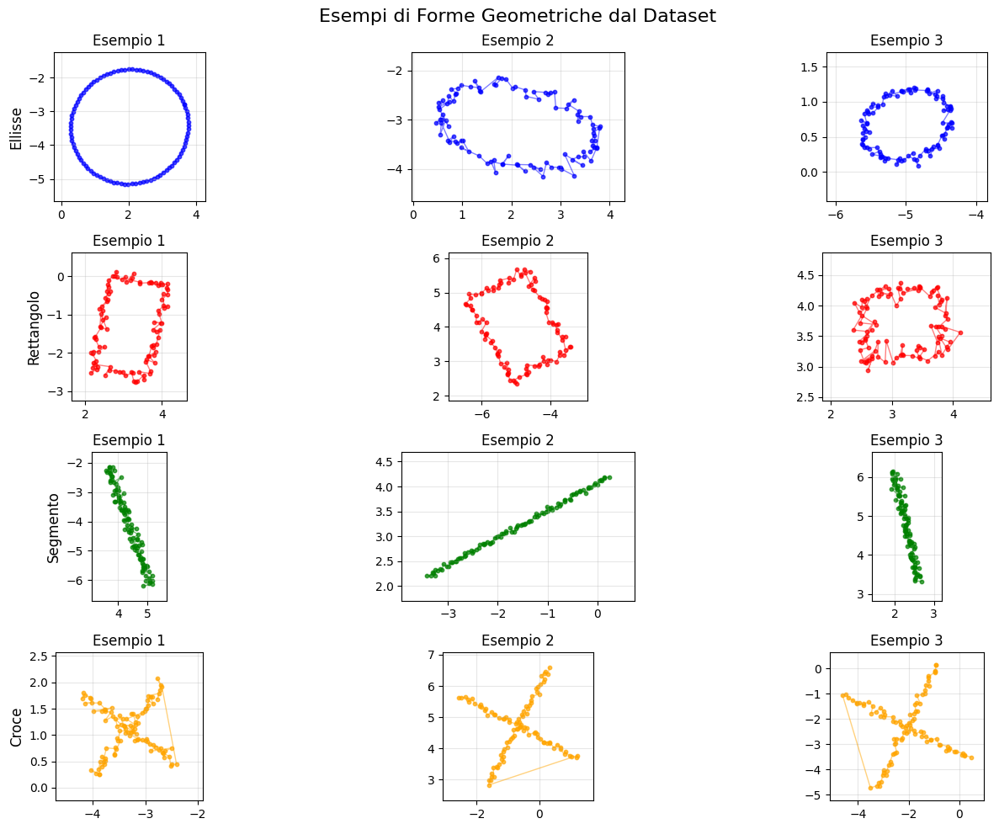

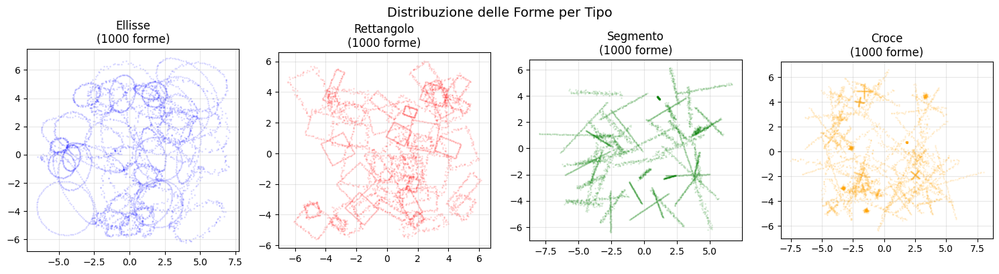

In [11]:
import matplotlib.pyplot as plt
import numpy as np

def visualizza_forme(X, y, n_per_tipo=4, figsize=(15, 10)):
    """
    Visualizza esempi di forme geometriche dal dataset.
    
    Parametri:
        X (np.ndarray): Array di forme (n_samples, n_punti, 2)
        y (np.ndarray): Array di etichette (n_samples,)
        n_per_tipo (int): Numero di esempi da mostrare per ogni tipo di forma
        figsize (tuple): Dimensione della figura
    """
    
    labels = ['ellisse', 'rettangolo', 'segmento', 'croce']
    colori = ['blue', 'red', 'green', 'orange']
    
    # Crea una griglia di subplot
    fig, axes = plt.subplots(4, n_per_tipo, figsize=figsize)
    fig.suptitle('Esempi di Forme Geometriche dal Dataset', fontsize=16)
    
    # Per ogni tipo di forma
    for tipo_forma in range(4):
        # Trova gli indici delle forme di questo tipo
        indici = np.where(y == tipo_forma)[0]
        
        # Prendi i primi n_per_tipo esempi
        esempi = indici[:n_per_tipo]
        
        for i, idx in enumerate(esempi):
            ax = axes[tipo_forma, i]
            
            # Estrai i punti della forma
            punti = X[idx]
            
            # Disegna i punti
            ax.scatter(punti[:, 0], punti[:, 1], 
                      c=colori[tipo_forma], s=10, alpha=0.7)
            
            # Collega i punti per vedere meglio la forma
            if tipo_forma in [0, 1]:  # ellisse e rettangolo: chiudi la forma
                punti_chiusi = np.vstack([punti, punti[0]])
                ax.plot(punti_chiusi[:, 0], punti_chiusi[:, 1], 
                       c=colori[tipo_forma], linewidth=1, alpha=0.5)
            else:  # segmento e croce: non chiudere
                ax.plot(punti[:, 0], punti[:, 1], 
                       c=colori[tipo_forma], linewidth=1, alpha=0.5)
            
            # Imposta titolo e formato
            if i == 0:
                ax.set_ylabel(f'{labels[tipo_forma].capitalize()}', fontsize=12)
            
            ax.set_title(f'Esempio {i+1}')
            ax.grid(True, alpha=0.3)
            ax.set_aspect('equal')
            
            # Imposta i limiti degli assi per una visualizzazione uniforme
            ax.set_xlim(punti[:, 0].min() - 0.5, punti[:, 0].max() + 0.5)
            ax.set_ylim(punti[:, 1].min() - 0.5, punti[:, 1].max() + 0.5)
    
    plt.tight_layout()
    plt.show()

def visualizza_distribuzione_forme(X, y, figsize=(15, 4)):
    """
    Visualizza la distribuzione di tutte le forme in un unico plot per tipo.
    
    Parametri:
        X (np.ndarray): Array di forme
        y (np.ndarray): Array di etichette
        figsize (tuple): Dimensione della figura
    """
    
    labels = ['ellisse', 'rettangolo', 'segmento', 'croce']
    colori = ['blue', 'red', 'green', 'orange']
    
    fig, axes = plt.subplots(1, 4, figsize=figsize)
    
    for tipo in range(4):
        ax = axes[tipo]
        
        # Trova tutte le forme di questo tipo
        indici = np.where(y == tipo)[0]
        
        # Disegna tutte le forme sovrapposte
        for idx in indici[:50]:  # Limita a 50 per non sovraccaricare
            punti = X[idx]
            ax.scatter(punti[:, 0], punti[:, 1], 
                      c=colori[tipo], s=1, alpha=0.1)
        
        ax.set_title(f'{labels[tipo].capitalize()}\n({len(indici)} forme)')
        ax.grid(True, alpha=0.3)
        ax.set_aspect('equal')
    
    plt.suptitle('Distribuzione delle Forme per Tipo', fontsize=14)
    plt.tight_layout()
    plt.show()


X, y = genera_campioni(n_shapes=1000, n_punti=100, rumore_std_bound=0.1)
    
visualizza_forme(X, y, n_per_tipo=3)
visualizza_distribuzione_forme(X, y)


Come prima cosa, definiamo un'insieme di features che potrebbero essere rilevanti al fine della classificazione e procediamo con un'esplorazione di queste features per vedere se esistono delle relazioni evidenti tra queste e i tipi di figure geometriche. Nel corso del progetto, valuteremo due tipi di rappresentazioni del dataset, una esplicita e una aggregata.

Esplicita: rappresentiamo le figure come il loro insieme delle coordinate dei punti relative al centroide.

Aggregata: rappresentiamo le figure in funzione di alcune features che rappresentano implicitamente la figura, come per esempio la distanza media  di un punto dal centroide.

# Feature definition

In [12]:
import numpy as np
import pandas as pd

#----------------------------
# rappresentazione esplicita
#----------------------------

def calcola_coordinate_relative(X):
    """
    Calcola le coordinate relative al centroide per ogni forma.
    """
    n_samples, n_punti, _ = X.shape
    X_relative = np.zeros_like(X)
    
    for i in range(n_samples):
        centroide = np.mean(X[i], axis=0)
        X_relative[i] = X[i] - centroide
    return X_relative.reshape(n_samples, -1)

#----------------------------
# rappresentazione aggregata
#----------------------------

def calcola_rapporto_bbox_area_minima(X, n_rotazioni=45):
    """
    Calcola il rapporto lato lungo/lato corto del bounding box di area minima.
    """
    n_samples, n_punti, _ = X.shape
    rapporti = np.zeros((n_samples, 1))
    
    for i in range(n_samples):
        coords = X[i]
        min_area = float('inf')
        migliore_ratio = 1.0
        
        angoli = np.linspace(0, np.pi/2, n_rotazioni)
        
        for angolo in angoli:
            # Matrice rotazione
            cos_a, sin_a = np.cos(angolo), np.sin(angolo)
            R = np.array([[cos_a, -sin_a], [sin_a, cos_a]])
            
            # Ruota punti
            punti_ruotati = np.dot(coords, R.T)
            
            # Bounding box
            min_x, max_x = np.min(punti_ruotati[:, 0]), np.max(punti_ruotati[:, 0])
            min_y, max_y = np.min(punti_ruotati[:, 1]), np.max(punti_ruotati[:, 1])
            
            width = max_x - min_x
            height = max_y - min_y
            area = width * height
            
            if area < min_area:
                min_area = area
                migliore_ratio = max(width, height) / (min(width, height) + 1e-8)
        
        rapporti[i] = migliore_ratio
    
    return rapporti
# Funzioni per calcolare informazioni riguardanti il centroide e le distanze
def calcola_distanze_dal_centro(X):
    """
    Calcola le distanze di ogni punto dal centro della forma.
    """
    n_samples, n_punti, _ = X.shape
    distanze = np.zeros((n_samples, n_punti))
    
    for i in range(n_samples):
        centro = np.mean(X[i], axis=0)
        vettori = X[i] - centro
        distanze_raw = np.sqrt(np.sum(vettori**2, axis=1))
        distanze[i] = np.nan_to_num(distanze_raw, nan=0.0)
    
    return distanze

def calcola_distanza_media_dal_centroide(X):
 
    n_samples, n_punti, _ = X.shape
    distanze_medie = np.zeros(n_samples)
    distanze = calcola_distanze_dal_centro(X)
    for i in range(n_samples):
        distanze_medie[i] = np.mean(distanze[i])
    
    return distanze_medie.reshape(-1, 1)

def calcola_varianza_distanza_dal_centroide(X):
    n_samples, n_punti, _ = X.shape
    varianze_distanze = np.zeros(n_samples)
    distanze = calcola_distanze_dal_centro(X)
    for i in range(n_samples):
        varianze_distanze[i] = np.var(distanze[i])
  
    return varianze_distanze.reshape(-1, 1)

def calcola_distanza_minima_centro(X):
    """
    Calcola la distanza minima dal centro per ogni forma.
    """
    distanze = calcola_distanze_dal_centro(X)
    return np.min(distanze, axis=1).reshape(-1, 1)

def calcola_distanza_max_centro(X):
    """
    Calcola la distanza massima dal centro per ogni forma.
    """
    distanze = calcola_distanze_dal_centro(X)
    return np.max(distanze, axis=1).reshape(-1, 1)

# Caratteristiche del contorno della forma
def calcola_perimetro(X):

    """
    Calcola il perimetro di ogni forma.
    """
    n_samples, n_punti, _ = X.shape
    perimetri = np.zeros((n_samples, 1))
    
    for i in range(n_samples):
        coords = X[i]
        perimetro = 0.0
        
        for j in range(n_punti):
            punto_corrente = coords[j]
            punto_successivo = coords[(j + 1) % n_punti]
            distanza_segmento = np.sqrt(np.sum((punto_successivo - punto_corrente)**2))    
            perimetro += distanza_segmento
                
        perimetri[i] = max(0.0, perimetro)
    
    return perimetri

def calcola_distanza_bounding_box(X):
    """
    Calcola la distanza minima di ogni punto dal bounding box della forma.
    """
    n_samples, n_punti, _ = X.shape
    distanze_min = np.zeros((n_samples, n_punti))
    
    for i in range(n_samples):
        coords = X[i]
        
        # Calcola bounding box
        min_x, max_x = np.min(coords[:, 0]), np.max(coords[:, 0])
        min_y, max_y = np.min(coords[:, 1]), np.max(coords[:, 1])
        
        for j in range(n_punti):
            x, y = coords[j]
            
            # Distanza dai bordi del bounding box
            dist_left = abs(x - min_x)
            dist_right = abs(x - max_x) 
            dist_bottom = abs(y - min_y)
            dist_top = abs(y - max_y)
            
            distanze_min[i, j] = min(dist_left, dist_right, dist_bottom, dist_top)
    
    return distanze_min

def calcola_media_distanza_bbox(X):
    """
    Calcola la media delle distanze dal bounding box per ogni forma.
    """
    distanze = calcola_distanza_bounding_box(X)
    return np.mean(distanze, axis=1).reshape(-1, 1)

def calcola_varianza_distanza_bbox(X):
    """
    Calcola la varianza delle distanze dal bounding box per ogni forma.
    """
    distanze = calcola_distanza_bounding_box(X)
    return np.var(distanze, axis=1).reshape(-1, 1)

# Distanze tra primo e ultimo punto
def calcola_distanze_punti_opposti(X):
    """Calcola la distanza tra primo e ultimo punto per ogni forma."""
    n_samples, n_punti, _ = X.shape
    distanze_opposte = np.zeros((n_samples, 1))
    
    for i in range(n_samples):
        # Distanza euclidea tra primo e ultimo punto
        distanza = np.sqrt(np.sum((X[i][0] - X[i][-1])**2))
        distanze_opposte[i] = distanza
    
    return distanze_opposte

# Informazioni sugli angoli
def calcola_angoli(X):
    """
    Calcola gli angoli di ogni punto rispetto al centroide.
    
    Returns:
        np.array: shape (n_samples, n_punti) con angoli in radianti [0, 2π]
    """
    n_samples, n_punti, _ = X.shape
    angoli = np.zeros((n_samples, n_punti))
    
    for i in range(n_samples):
        centroide = np.mean(X[i], axis=0)
        punti_relativi = X[i] - centroide
        
        # Calcola angoli usando arctan2
        angoli_rad = np.arctan2(punti_relativi[:, 1], punti_relativi[:, 0])
        
        # Converte da [-π, π] a [0, 2π]
        angoli[i] = np.where(angoli_rad < 0, angoli_rad + 2*np.pi, angoli_rad)
    
    return angoli

def calcola_varianza_angoli(X):
    """
    Calcola la varianza degli angoli per ogni forma.
    
    Returns:
        np.array: shape (n_samples, 1) con varianza angoli per ogni campione
    """
    angoli = calcola_angoli(X)
    varianze = np.var(angoli, axis=1)
    return varianze.reshape(-1, 1)

def calcola_media_angoli(X):
    """
    Calcola la media degli angoli per ogni forma.
    
    Returns:
        np.array: shape (n_samples, 1) con media angoli per ogni campione
    """
    angoli = calcola_angoli(X)
    medie = np.mean(angoli, axis=1)
    return medie.reshape(-1, 1)

def calcola_punti_vicini_al_centro(X):
    """Percentuale di punti molto vicini al centro"""
    n_samples, n_punti = X.shape[0], X.shape[1]
    percentuali = np.zeros((n_samples, 1))
    
    distanze = calcola_distanze_dal_centro(X)
    
    for i in range(n_samples):
        soglia = np.mean(distanze[i]) * 0.3  # 30% della distanza media
        punti_vicini = np.sum(distanze[i] < soglia)
        percentuali[i] = punti_vicini / n_punti
    
    return percentuali



In [13]:
X,y = genera_campioni(n_shapes=1000, n_punti=100, rumore_std_bound=0.1)

In [14]:
print("Shape di X:", X.shape)
print("Shape di y:", y.shape)

Shape di X: (4000, 100, 2)
Shape di y: (4000,)


Per farci un'idea della rilevanza delle feature possiamo fare un'analisi esplorativa delle caratteristiche definite per vedere se possono essere utili ai nostri scopi oppure no

## Features riguardanti gli angoli dei punti

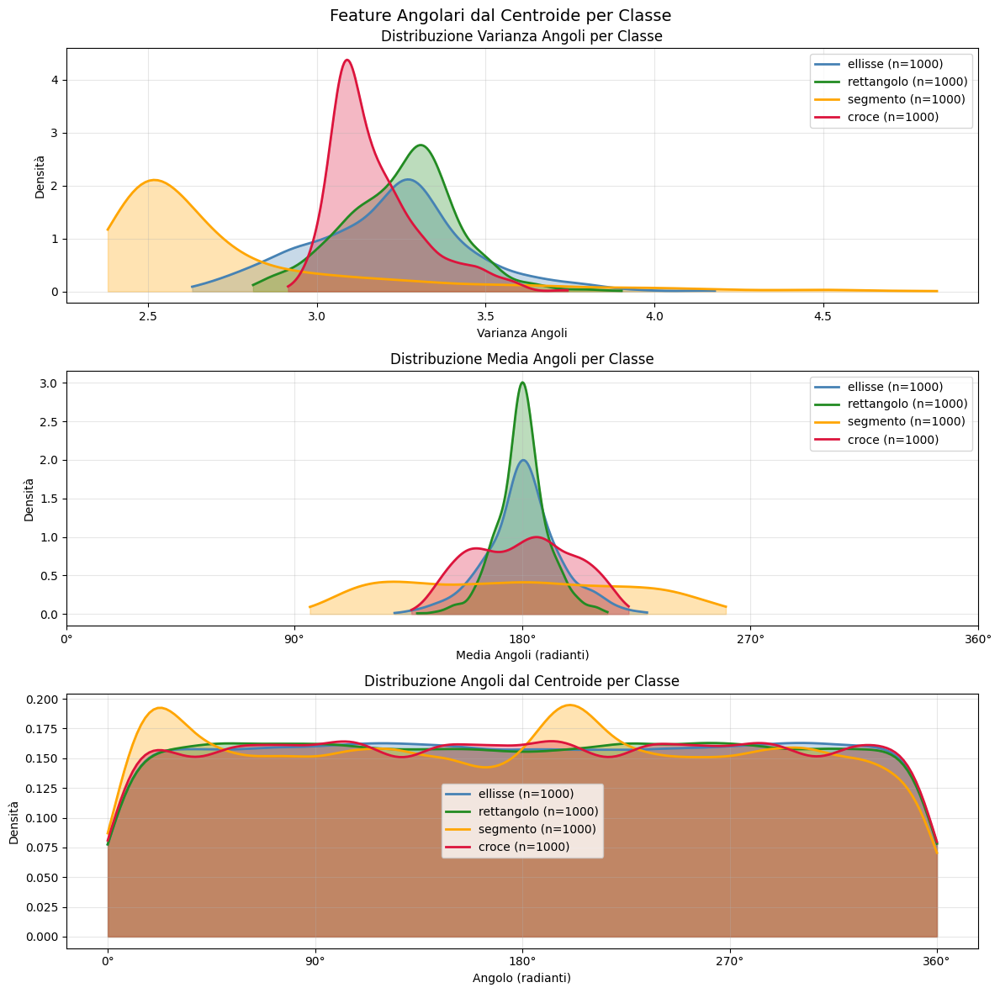

In [15]:
import matplotlib.pyplot as plt
import numpy as np

def report_angoli_centroide(X, y, figsize=(12, 12)):
    """Report grafico delle feature angolari dal centroide."""
    
    # Calcola feature angolari
    varianze_angoli = calcola_varianza_angoli(X).flatten()
    medie_angoli = calcola_media_angoli(X).flatten()
    
    # Calcola angoli per distribuzione
    angoli = calcola_angoli(X)
    
    labels = ['ellisse', 'rettangolo', 'segmento', 'croce']
    colors = ['steelblue', 'forestgreen', 'orange', 'crimson']
    
    fig = plt.figure(figsize=figsize)
    
    # Prima riga: distribuzione varianze angoli
    ax_var = plt.subplot(3, 1, 1)
    
    for classe_idx, (label, color) in enumerate(zip(labels, colors)):
        mask = y == classe_idx
        dati_classe = varianze_angoli[mask]
        
        # Calcola densità continua
        from scipy.stats import gaussian_kde
        kde = gaussian_kde(dati_classe)
        x_range = np.linspace(dati_classe.min(), dati_classe.max(), 200)
        density = kde(x_range)
        
        ax_var.plot(x_range, density, color=color, linewidth=2, 
                   label=f'{label} (n={np.sum(mask)})')
        ax_var.fill_between(x_range, density, alpha=0.3, color=color)
    
    ax_var.set_xlabel('Varianza Angoli')
    ax_var.set_ylabel('Densità')
    ax_var.set_title('Distribuzione Varianza Angoli per Classe')
    ax_var.legend()
    ax_var.grid(True, alpha=0.3)
    
    # Seconda riga: distribuzione medie angoli
    ax_media = plt.subplot(3, 1, 2)
    
    for classe_idx, (label, color) in enumerate(zip(labels, colors)):
        mask = y == classe_idx
        dati_classe = medie_angoli[mask]
        
        # Calcola densità continua
        kde = gaussian_kde(dati_classe)
        x_range = np.linspace(dati_classe.min(), dati_classe.max(), 200)
        density = kde(x_range)
        
        ax_media.plot(x_range, density, color=color, linewidth=2, 
                     label=f'{label} (n={np.sum(mask)})')
        ax_media.fill_between(x_range, density, alpha=0.3, color=color)
    
    ax_media.set_xlabel('Media Angoli (radianti)')
    ax_media.set_ylabel('Densità')
    ax_media.set_title('Distribuzione Media Angoli per Classe')
    ax_media.legend()
    ax_media.grid(True, alpha=0.3)
    
    # Aggiungi etichette angoli principali per le medie
    ax_media.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
    ax_media.set_xticklabels(['0°', '90°', '180°', '270°', '360°'])
    
    # Terza riga: distribuzione angoli
    ax_dist = plt.subplot(3, 1, 3)
    
    for classe_idx, (label, color) in enumerate(zip(labels, colors)):
        mask = y == classe_idx
        dati_classe = angoli[mask].flatten()
        
        # Calcola densità continua
        kde = gaussian_kde(dati_classe)
        x_range = np.linspace(0, 2*np.pi, 200)
        density = kde(x_range)
        
        ax_dist.plot(x_range, density, color=color, linewidth=2, 
                    label=f'{label} (n={np.sum(mask)})')
        ax_dist.fill_between(x_range, density, alpha=0.3, color=color)
    
    ax_dist.set_xlabel('Angolo (radianti)')
    ax_dist.set_ylabel('Densità')
    ax_dist.set_title('Distribuzione Angoli dal Centroide per Classe')
    ax_dist.legend()
    ax_dist.grid(True, alpha=0.3)
    
    # Aggiungi etichette angoli principali
    ax_dist.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
    ax_dist.set_xticklabels(['0°', '90°', '180°', '270°', '360°'])
    
    plt.suptitle('Feature Angolari dal Centroide per Classe', fontsize=14)
    plt.tight_layout()
    plt.show()
    

report_angoli_centroide(X, y)

## Features riguardanti le distanze

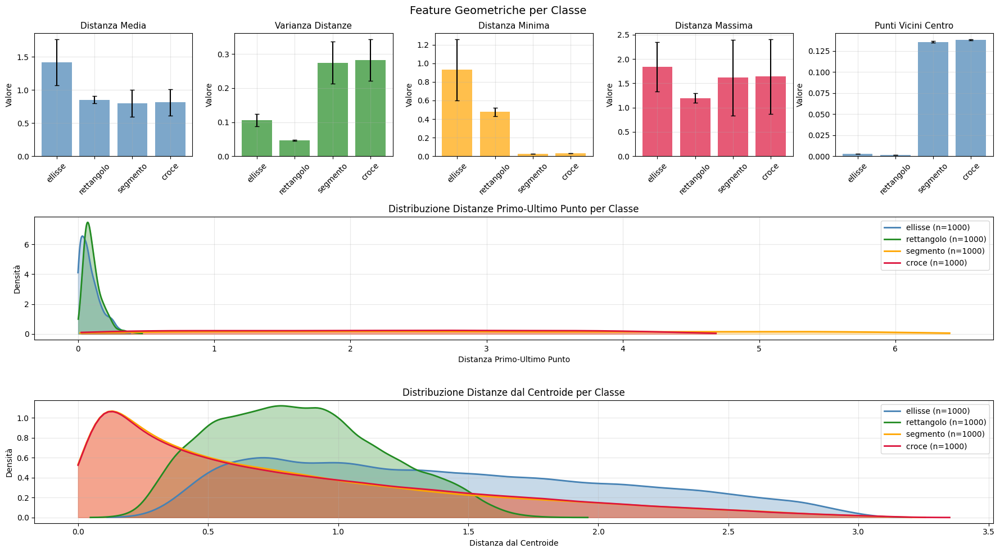

In [16]:
def report_distanze_centroide(X, y, figsize=(18, 10)):
    """Report grafico delle feature di distanza dal centroide + distribuzione distanza primo-ultimo punto."""
    
    # Calcola feature dal centroide
    features = [
        calcola_distanza_media_dal_centroide(X).flatten(),
        calcola_varianza_distanza_dal_centroide(X).flatten(),
        calcola_distanza_minima_centro(X).flatten(),
        calcola_distanza_max_centro(X).flatten(),
        calcola_punti_vicini_al_centro(X).flatten()  # Nuova feature
    ]
    
    # Calcola distanze
    distanze_opposte = calcola_distanze_punti_opposti(X).flatten()
    distanze_centroide = calcola_distanze_dal_centro(X)
    
    titles = ['Distanza Media', 'Varianza Distanze', 'Distanza Minima', 'Distanza Massima', 'Punti Vicini Centro']
    labels = ['ellisse', 'rettangolo', 'segmento', 'croce']
    colors = ['steelblue', 'forestgreen', 'orange', 'crimson']
    
    fig = plt.figure(figsize=figsize)
    
    # Prima riga: 5 grafici feature dal centroide
    for idx, (feature, title) in enumerate(zip(features, titles)):
        ax = plt.subplot(3, 5, idx + 1)
        
        # Organizza dati per classe
        feature_per_classe = [[] for _ in range(4)]
        for i in range(len(X)):
            feature_per_classe[y[i]].append(feature[i])
        
        # Calcola statistiche
        medie = [np.mean(f_list) for f_list in feature_per_classe]
        varianze = [np.var(f_list) for f_list in feature_per_classe]
        
        # Crea grafico
        bars = ax.bar(labels, medie, yerr=varianze, capsize=3,
                      color=colors[idx % len(colors)], alpha=0.7, ecolor='black')
        
        ax.set_title(title, fontsize=11)
        ax.set_ylabel('Valore')
        ax.grid(True, alpha=0.3)
        ax.tick_params(axis='x', rotation=45)
    
    # Seconda riga: distribuzione distanze primo-ultimo punto
    ax_dist_opp = plt.subplot(3, 1, 2)
    
    for classe_idx, (label, color) in enumerate(zip(labels, colors)):
        mask = y == classe_idx
        dati_classe = distanze_opposte[mask]
        
        # Calcola densità continua
        from scipy.stats import gaussian_kde
        kde = gaussian_kde(dati_classe)
        x_range = np.linspace(dati_classe.min(), dati_classe.max(), 200)
        density = kde(x_range)
        
        ax_dist_opp.plot(x_range, density, color=color, linewidth=2, 
                        label=f'{label} (n={np.sum(mask)})')
        ax_dist_opp.fill_between(x_range, density, alpha=0.3, color=color)
    
    ax_dist_opp.set_xlabel('Distanza Primo-Ultimo Punto')
    ax_dist_opp.set_ylabel('Densità')
    ax_dist_opp.set_title('Distribuzione Distanze Primo-Ultimo Punto per Classe')
    ax_dist_opp.legend()
    ax_dist_opp.grid(True, alpha=0.3)
    
    # Terza riga: distribuzione distanze dal centroide
    ax_dist_centro = plt.subplot(3, 1, 3)
    
    for classe_idx, (label, color) in enumerate(zip(labels, colors)):
        mask = y == classe_idx
        dati_classe = distanze_centroide[mask].flatten()
        
        # Calcola densità continua
        kde = gaussian_kde(dati_classe)
        x_range = np.linspace(dati_classe.min(), dati_classe.max(), 200)
        density = kde(x_range)
        
        ax_dist_centro.plot(x_range, density, color=color, linewidth=2, 
                           label=f'{label} (n={np.sum(mask)})')
        ax_dist_centro.fill_between(x_range, density, alpha=0.3, color=color)
    
    ax_dist_centro.set_xlabel('Distanza dal Centroide')
    ax_dist_centro.set_ylabel('Densità')
    ax_dist_centro.set_title('Distribuzione Distanze dal Centroide per Classe')
    ax_dist_centro.legend()
    ax_dist_centro.grid(True, alpha=0.3)
    
    plt.suptitle('Feature Geometriche per Classe', fontsize=14)
    plt.tight_layout()
    plt.show()

report_distanze_centroide(X,y)

## Features del perimetro

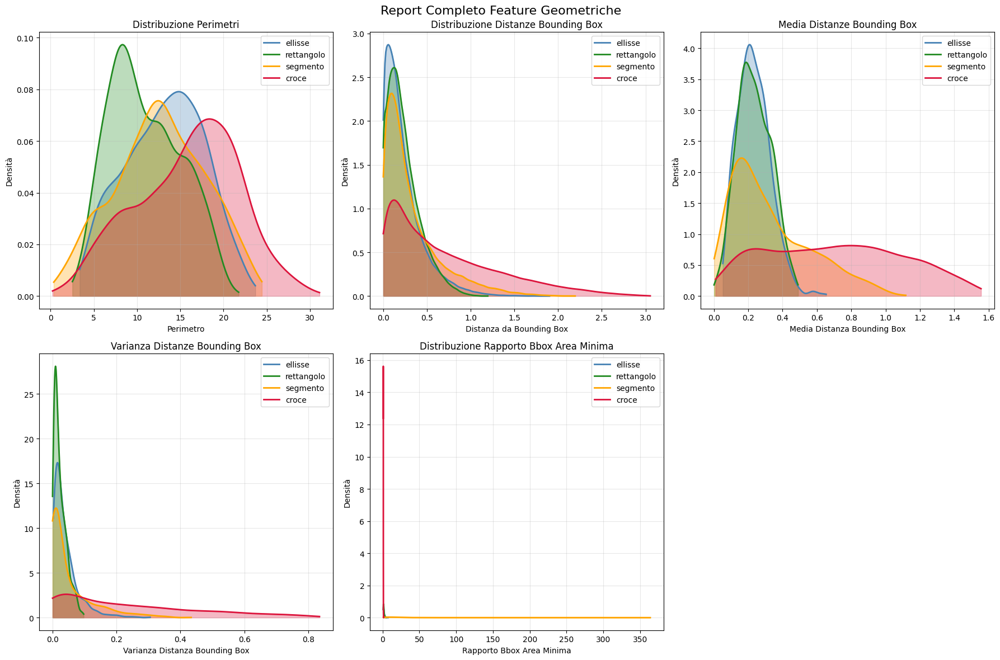

In [17]:
def report_completo(X, y, figsize=(18, 12)):
    """Report completo con perimetri, analisi bounding box e rapporto bbox area minima usando curve."""
    
    perimetri = calcola_perimetro(X).flatten()
    distanze_bbox = calcola_distanza_bounding_box(X)
    medie_bbox = np.mean(distanze_bbox, axis=1)
    varianze_bbox = np.var(distanze_bbox, axis=1)
    rapporto_bbox = calcola_rapporto_bbox_area_minima(X).flatten()
    
    labels = ['ellisse', 'rettangolo', 'segmento', 'croce']
    colors = ['steelblue', 'forestgreen', 'orange', 'crimson']
    
    fig, axes = plt.subplots(2, 3, figsize=figsize)
    
    # 1. Distribuzione perimetri (curve)
    ax1 = axes[0, 0]
    for classe_idx, (label, color) in enumerate(zip(labels, colors)):
        mask = y == classe_idx
        dati_classe = perimetri[mask]
        
        from scipy.stats import gaussian_kde
        kde = gaussian_kde(dati_classe)
        x_range = np.linspace(dati_classe.min(), dati_classe.max(), 200)
        density = kde(x_range)
        
        ax1.plot(x_range, density, color=color, linewidth=2, label=f'{label}')
        ax1.fill_between(x_range, density, alpha=0.3, color=color)
    
    ax1.set_xlabel('Perimetro')
    ax1.set_ylabel('Densità')
    ax1.set_title('Distribuzione Perimetri')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # 2. Distribuzione distanze bbox (curve)
    ax2 = axes[0, 1]
    for classe_idx, (label, color) in enumerate(zip(labels, colors)):
        mask = y == classe_idx
        dati_classe = distanze_bbox[mask].flatten()
        
        kde = gaussian_kde(dati_classe)
        x_range = np.linspace(dati_classe.min(), dati_classe.max(), 200)
        density = kde(x_range)
        
        ax2.plot(x_range, density, color=color, linewidth=2, label=f'{label}')
        ax2.fill_between(x_range, density, alpha=0.3, color=color)
    
    ax2.set_xlabel('Distanza da Bounding Box')
    ax2.set_ylabel('Densità')
    ax2.set_title('Distribuzione Distanze Bounding Box')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # 3. Media distanze bbox (curve)
    ax3 = axes[0, 2]
    for classe_idx, (label, color) in enumerate(zip(labels, colors)):
        mask = y == classe_idx
        dati_classe = medie_bbox[mask]
        
        kde = gaussian_kde(dati_classe)
        x_range = np.linspace(dati_classe.min(), dati_classe.max(), 200)
        density = kde(x_range)
        
        ax3.plot(x_range, density, color=color, linewidth=2, label=f'{label}')
        ax3.fill_between(x_range, density, alpha=0.3, color=color)
    
    ax3.set_xlabel('Media Distanza Bounding Box')
    ax3.set_ylabel('Densità')
    ax3.set_title('Media Distanze Bounding Box')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    # 4. Varianza distanze bbox (curve)
    ax4 = axes[1, 0]
    for classe_idx, (label, color) in enumerate(zip(labels, colors)):
        mask = y == classe_idx
        dati_classe = varianze_bbox[mask]
        
        kde = gaussian_kde(dati_classe)
        x_range = np.linspace(dati_classe.min(), dati_classe.max(), 200)
        density = kde(x_range)
        
        ax4.plot(x_range, density, color=color, linewidth=2, label=f'{label}')
        ax4.fill_between(x_range, density, alpha=0.3, color=color)
    
    ax4.set_xlabel('Varianza Distanza Bounding Box')
    ax4.set_ylabel('Densità')
    ax4.set_title('Varianza Distanze Bounding Box')
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    
    # 5. Rapporto bbox area minima (curve) - NUOVO
    ax5 = axes[1, 1]
    for classe_idx, (label, color) in enumerate(zip(labels, colors)):
        mask = y == classe_idx
        dati_classe = rapporto_bbox[mask]
        
        kde = gaussian_kde(dati_classe)
        x_range = np.linspace(dati_classe.min(), dati_classe.max(), 200)
        density = kde(x_range)
        
        ax5.plot(x_range, density, color=color, linewidth=2, label=f'{label}')
        ax5.fill_between(x_range, density, alpha=0.3, color=color)
    
    ax5.set_xlabel('Rapporto Bbox Area Minima')
    ax5.set_ylabel('Densità')
    ax5.set_title('Distribuzione Rapporto Bbox Area Minima')
    ax5.legend()
    ax5.grid(True, alpha=0.3)
    
    # Rimuovi subplot vuoto
    axes[1, 2].remove()
    
    plt.suptitle('Report Completo Feature Geometriche', fontsize=16)
    plt.tight_layout()
    plt.show()

report_completo(X, y)

# Ottieni features

Le distribuzioni dei parametri non pare siano così differenti, in ogni caso non essendo sicuro della inutilità di questa feature, la tengo per analisi successive.

sulla base di quanto visto creo un dataframe pandas contenente le features che ritengo essere più importanti

In [18]:

def ottieni_features_aggregate(X):
    min_distanza = calcola_distanza_minima_centro(X)
    perimetro = calcola_perimetro(X)
    max_distanza = calcola_distanza_max_centro(X)
    varianza_angoli = calcola_varianza_angoli(X)
    distanza_media = calcola_distanza_media_dal_centroide(X)
    varianza_distanza_dal_centroide = calcola_varianza_distanza_dal_centroide(X)
    distanze_punti_opposti = calcola_distanze_punti_opposti(X)
    distanza_media_bbox = calcola_media_distanza_bbox(X)
    varianza_distanza_bbox = calcola_varianza_distanza_bbox(X)
    punti_vicini_al_centro = calcola_punti_vicini_al_centro(X)
    rapporto_bbox_area_minima = calcola_rapporto_bbox_area_minima(X)
    
    # Concatena tutte le features
    features_array = np.concatenate([
        min_distanza,
        perimetro,
        max_distanza,
        varianza_angoli,
        distanza_media,
        varianza_distanza_dal_centroide,
        distanze_punti_opposti,
        distanza_media_bbox,
        varianza_distanza_bbox,
        punti_vicini_al_centro,
        rapporto_bbox_area_minima
    ], axis=1)
    
    # Crea i nomi delle colonne
    n_punti = X.shape[1]
    column_names = (
        ['min_distanza'] +  # Distanze
        ['perimetro'] +  # Perimetro
        ['max_distanza'] +  # Distanza massima
        ['varianza_angoli'] +  # Varianza angoli
        ['distanza_media'] +  # Distanza media dal centroide
        ['varianza_distanza_centro'] + # Varianza distanza dal centroide
        ['distanza_punti_opposti']  +  # Distanza tra primo e ultimo punto
        ['distanza_media_bbox'] + # Media distanza dal bounding box
        ['varianza_distanza_bbox'] +# Varianza distanza dal bounding box
        ['punti_vicino_al_centro'] +
        ['rapporto_bbox_area_minima']
    )
    
    # Crea e restituisce il DataFrame
    df = pd.DataFrame(features_array, columns=column_names)
    return df


In [56]:
X,y = genera_campioni(n_shapes=1000, n_punti=100, rumore_std_bound=rumore_const)
X_f = ottieni_features_aggregate(X)
X_f

,min_distanza,perimetro,max_distanza,varianza_angoli,distanza_media,varianza_distanza_centro,distanza_punti_opposti,distanza_media_bbox,varianza_distanza_bbox,punti_vicino_al_centro,rapporto_bbox_area_minima
0,0.143216,161.672578,3.902855,3.660427,1.683616,0.801895,0.655248,1.677459,0.562805,0.08,1.206159
1,0.164965,21.279087,0.898036,3.350958,0.511319,0.014366,0.141669,0.266920,0.012300,0.00,1.016388
2,0.228442,34.390862,1.151381,3.183334,0.617870,0.038954,0.514120,0.440404,0.038861,0.00,1.030925
3,0.433511,81.156602,3.447132,3.277875,2.118078,0.591960,1.139541,0.988521,0.331762,0.02,1.937387
4,0.368690,109.154443,4.448205,3.245334,2.067030,0.615613,1.263543,1.093261,0.542537,0.04,1.027611
...,...,...,...,...,...,...,...,...,...,...,...
3995,0.005790,7.465309,1.020388,3.040303,0.507448,0.083870,1.417429,0.394899,0.054341,0.14,1.028029
3996,0.112287,159.523057,3.744535,3.268455,1.452906,0.493070,3.699022,1.201801,0.374396,0.05,1.209390
3997,0.136934,93.889277,4.017026,3.160042,1.642842,0.808386,5.029341,1.717811,0.685865,0.09,1.191689
3998,0.223738,135.861751,3.161637,3.248449,1.524373,0.580925,4.554273,1.593874,0.512499,0.04,1.058340


## Modelli di partenza

In questa sezione andiamo ad applicare tecniche di feature selection ed extraction sulle rappresentazioni del dataset che abbiamo creato. In particolare, per la rappresentazione aggregata facciamo feature selection e quindi valutiamo quali attributi siano più importanti nell'ambito di questo task di classificazione. Per quanto riguarda la rappresentazione esplicita invece utilizziamo la tecnica di PCA per ridurre la dimensionalità del dataset.

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
import warnings
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.decomposition import PCA
warnings.filterwarnings('ignore')

# Feature selection

In questa sezione proviamo ad applicare tecniche per feature selection per individuare quali sono le features più importanti nell'ambito della classificazione e l'impatto della selezione sui vari modelli. In questo caso, quello che facciamo è considerare unicamente le features aggregate, tralasciando la posizione del punto relativo al centroide. 

Utilizzando una random forest posso estrarre le k migliori features basandomi sull'importanza che queste acquisiscono all'interno del modello. Come prima cosa mostro l'importanza delle features attraverso un grafico.

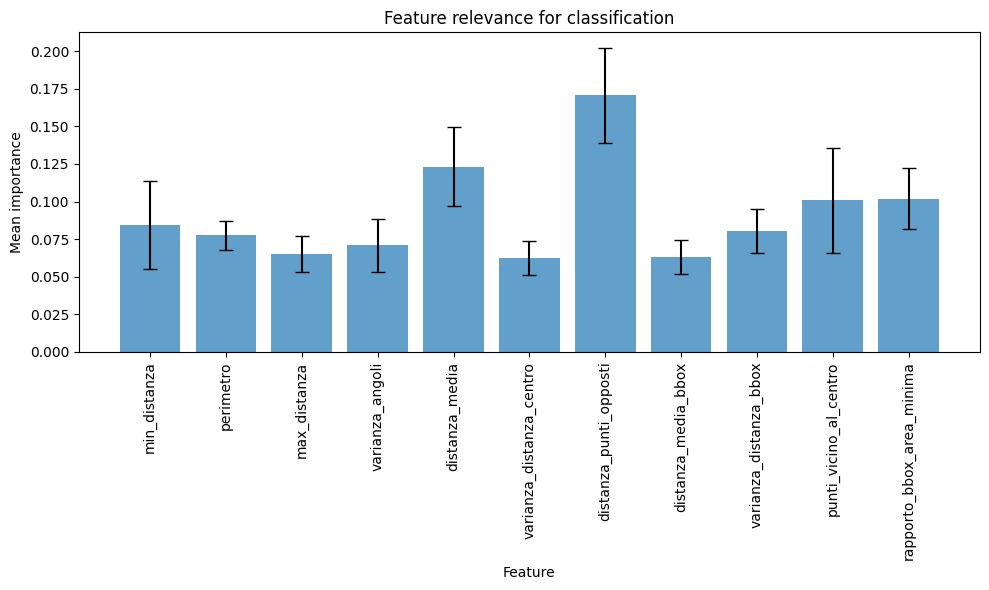

In [58]:
# Crea un classificatore ExtraTrees per valutare l'importanza delle feature
forest = ExtraTreesClassifier(n_estimators=250, random_state=0)

# Costruisce una pipeline che:
# - Applica il preprocessing alle feature (scaling, encoding)
# - Allena il classificatore ExtraTrees
pipeline = Pipeline([
    ('preproc', StandardScaler()),
    ('clf', forest)
])
X_f = ottieni_features_aggregate(X)
X_train, X_test, y_train, y_test = train_test_split(X_f,y,test_size=0.3,stratify=y,random_state=42)
# Allena la pipeline sui dati di training
pipeline.fit(X_train, y_train)

# Estrae l'importanza media delle feature dalla foresta addestrata
importances = pipeline.named_steps['clf'].feature_importances_

# Estrae l'importanza delle feature da ciascun albero della foresta
# (utile per analisi di varianza o distribuzione delle importanze)
feature_importances_per_tree = np.array([tree.feature_importances_ for tree in forest.estimators_])

# Crea un DataFrame con le importanze per ogni albero e i nomi delle feature trasformate
importances_df = pd.DataFrame(feature_importances_per_tree, columns=X_f.columns)

# Calcola la media e deviazione standard delle importanze delle feature per ogni colonna
dd = importances_df.agg(['mean', 'std']).T.reset_index()
dd.columns = ['Feature', 'Mean', 'Std']

# Crea la figura e l'asse con l'interfaccia a oggetti di matplotlib
fig, ax = plt.subplots(figsize=(10, 6))

# Grafico a barre delle medie delle importanze con barre di errore (deviazione standard)
ax.bar(dd['Feature'], dd['Mean'], yerr=dd['Std'], alpha=0.7, capsize=5)
ax.set_title('Feature relevance for classification')
ax.set_ylabel('Mean importance')
ax.set_xlabel('Feature')
ax.set_xticklabels(dd['Feature'], rotation=90)
fig.tight_layout()
plt.show()

In [59]:
estimator = ExtraTreesClassifier(n_estimators=250, random_state=42)
sfs= SequentialFeatureSelector(
    estimator, 
    n_features_to_select=7,
    direction='backward',  
    cv=3,                
    scoring='accuracy',
    n_jobs=-1
)
# Fit e trasforma
sfs.fit(X_train, y_train)
X_selected_forward = sfs.transform(X_train)

selected_features = X_train.columns[sfs.get_support()]
print(selected_features)

Index(['perimetro', 'varianza_angoli', 'distanza_media',
       'varianza_distanza_centro', 'distanza_punti_opposti',
       'varianza_distanza_bbox', 'rapporto_bbox_area_minima'],
      dtype='object')


### Valutazione della feature selection sulle prestazione dei modelli

In [60]:

X_f = ottieni_features_aggregate(X)

X_train, X_test, y_train, y_test = train_test_split(X_f, y, test_size=0.3, stratify=y, random_state=42)
X_train_selected = sfs.transform(X_train)
X_test_selected = sfs.transform(X_test)

acc_senza_selection = {}

# Random Forest
rf = RandomForestClassifier(random_state=42,n_estimators=100)
rf.fit(X_train, y_train)
acc_senza_selection['Random Forest'] = accuracy_score(y_test, rf.predict(X_test))

# Logistic Regression
lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(solver='saga',  random_state=42))
])
lr.fit(X_train, y_train)
acc_senza_selection['Logistic Regression'] = accuracy_score(y_test, lr.predict(X_test))

# SVM
svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', random_state=42))
])
svm.fit(X_train, y_train)
acc_senza_selection['SVM'] = accuracy_score(y_test, svm.predict(X_test))

# MLP
mlp = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', MLPClassifier(random_state=42))
])
mlp.fit(X_train, y_train)
acc_senza_selection['MLP'] = accuracy_score(y_test, mlp.predict(X_test))

#modelli con selection
acc_con_selection = {}

# Random Forest
rf = Pipeline([
    ('clf',RandomForestClassifier(random_state=42,n_estimators=100))
])

rf.fit(X_train_selected, y_train)
acc_con_selection['Random Forest'] = accuracy_score(y_test, rf.predict(X_test_selected))

# Logistic Regression
lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(solver='saga', max_iter=10000, random_state=42))
])
lr.fit(X_train_selected, y_train)
acc_con_selection['Logistic Regression'] = accuracy_score(y_test, lr.predict(X_test_selected))

# SVM
svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', random_state=42))
])
svm.fit(X_train_selected, y_train)
acc_con_selection['SVM'] = accuracy_score(y_test, svm.predict(X_test_selected))

# MLP
mlp = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', MLPClassifier(random_state=42))
])
mlp.fit(X_train_selected, y_train)
acc_con_selection['MLP'] = accuracy_score(y_test, mlp.predict(X_test_selected))

df_confronto = pd.DataFrame({
    'Modello': acc_senza_selection.keys(),
    'Accuracy SENZA SELECTION': list(acc_senza_selection.values()),
    'Accuracy CON SELECTION': list(acc_con_selection.values())
})

print(df_confronto)


               Modello  Accuracy SENZA SELECTION  Accuracy CON SELECTION
0        Random Forest                  0.724167                0.733333
1  Logistic Regression                  0.704167                0.716667
2                  SVM                  0.727500                0.726667
3                  MLP                  0.733333                0.734167


## Feature Exctraction

In questa sezione valutiamo l'utilizzo della PCA sulla rappresentazione esplicita del dataset, confrontando l'accuracy dei modelli addestrati usando tutte le features originali e poi usando invece quelle estratte attraverso la PCA.

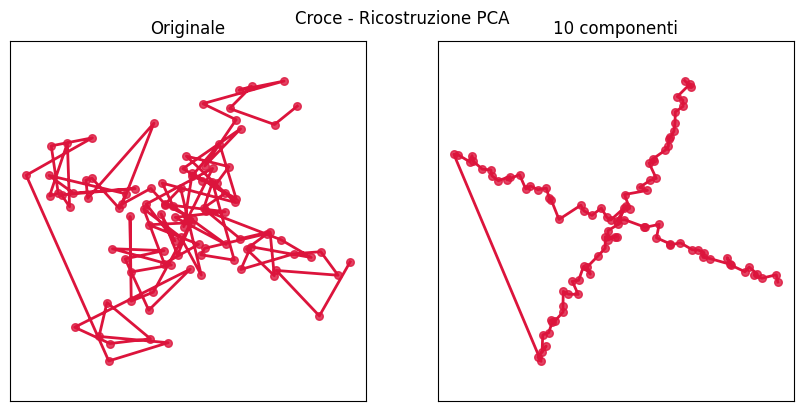

In [24]:
ncomponents = 10
pca = PCA(n_components=ncomponents, whiten=True, random_state=42)
X_f = calcola_coordinate_relative(X)
# Prepara i dati
X_train, X_test, y_train, y_test = train_test_split(X_f, y, test_size=0.3, random_state=42)

# Adatta la pipeline (solo scaler e PCA)
pipeline_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', pca)
])
pipeline_pca.fit(X_train)

# Seleziona l'indice della forma da ricostruire
k = 1 # Cambia questo valore per testare forme diverse

# Estrai scaler e PCA
scaler = pipeline_pca.named_steps['scaler']
pca = pipeline_pca.named_steps['pca']

# Proietta la forma nello spazio PCA e ricostruisci
forma_scaled = scaler.transform(X_train[k, :].reshape(1, -1))
forma_pca = pca.transform(forma_scaled)
forma_ricostruita_scaled = pca.inverse_transform(forma_pca)
forma_ricostruita = scaler.inverse_transform(forma_ricostruita_scaled)

# Converti in coordinate (n_punti, 2)
n_punti = X.shape[1]
coords_originali = X_train[k, :].reshape(n_punti, 2)
coords_ricostruite = forma_ricostruita.reshape(n_punti, 2)

# Determina classe e colore
classe = y_train[k]
labels = ['ellisse', 'rettangolo', 'segmento', 'croce']
colors = ['steelblue', 'forestgreen', 'orange', 'crimson']

# Visualizza originale vs ricostruzione
plt.figure(figsize=(8, 4))
plt.subplots_adjust(bottom=0, left=.01, right=.99, top=.90, hspace=.35)

# Forma originale
plt.subplot(1, 2, 1)
plt.title('Originale')
plt.scatter(coords_originali[:, 0], coords_originali[:, 1], 
           c=colors[classe], s=30, alpha=0.8)
if classe in [0, 1]:  # Chiudi ellisse e rettangolo
    coords_chiuse = np.vstack([coords_originali, coords_originali[0]])
    plt.plot(coords_chiuse[:, 0], coords_chiuse[:, 1], 
            c=colors[classe], linewidth=2)
else:
    plt.plot(coords_originali[:, 0], coords_originali[:, 1], 
            c=colors[classe], linewidth=2)
plt.axis('equal')
plt.grid(True, alpha=0.3)
plt.xticks([])
plt.yticks([])

# Forma ricostruita
plt.subplot(1, 2, 2)
plt.title(f'{ncomponents} componenti')
plt.scatter(coords_ricostruite[:, 0], coords_ricostruite[:, 1], 
           c=colors[classe], s=30, alpha=0.8)
if classe in [0, 1]:  # Chiudi ellisse e rettangolo
    coords_chiuse = np.vstack([coords_ricostruite, coords_ricostruite[0]])
    plt.plot(coords_chiuse[:, 0], coords_chiuse[:, 1], 
            c=colors[classe], linewidth=2)
else:
    plt.plot(coords_ricostruite[:, 0], coords_ricostruite[:, 1], 
            c=colors[classe], linewidth=2)
plt.axis('equal')
plt.grid(True, alpha=0.3)
plt.xticks([])
plt.yticks([])

plt.suptitle(f'{labels[classe].capitalize()} - Ricostruzione PCA')
plt.show()

Vediamo come la pca con soli 10 componenti riesce a fornire una buona rappresentazione della figura geometrica, addirittura eliminando parte del rumore introdotto dalla creazione del dataset.

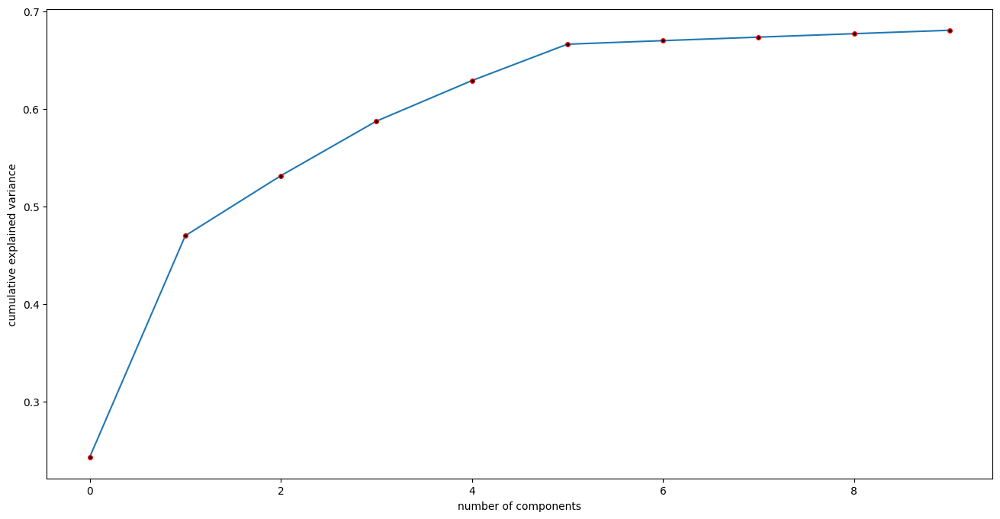

In [25]:
plt.figure(figsize=(16,8))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o', markersize=4, markerfacecolor="black", markeredgecolor="red")
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance')
plt.show()

Dai grafici precedenti si può osservare che la PCA con n_components = 10 è già in grado di catturare una buona parte della varianza. È possibile che la varianza tralasciata sia quella riguardante il rumore. Andiamo a sperimentare gli effetti delle nuove features su una serie di classificatori per valutare le prestazioni dei modelli precedenti su questa nuova rappresentazione. Addestriamo tutti i modelli prima senza usare la pca e poi usandola, confrontando i risultati.

In [26]:

X_f = calcola_coordinate_relative(X)

# 1. Coordinate relative + feature aggregate
X_esplicito = calcola_coordinate_relative(X) 
X_train, X_test, y_train, y_test = train_test_split(X_esplicito, y, test_size=0.3, stratify=y, random_state=42)

acc_senza_pca = {}

# Random Forest
rf = RandomForestClassifier(random_state=42,n_estimators=100)
rf.fit(X_train, y_train)
acc_senza_pca['Random Forest'] = accuracy_score(y_test, rf.predict(X_test))

# Logistic Regression
lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(solver='saga', max_iter=10000, random_state=42))
])
lr.fit(X_train, y_train)
acc_senza_pca['Logistic Regression'] = accuracy_score(y_test, lr.predict(X_test))

# SVM
svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', random_state=42))
])
svm.fit(X_train, y_train)
acc_senza_pca['SVM'] = accuracy_score(y_test, svm.predict(X_test))

# MLP
mlp = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', MLPClassifier(random_state=42))
])
mlp.fit(X_train, y_train)
acc_senza_pca['MLP'] = accuracy_score(y_test, mlp.predict(X_test))

### con PCA

# Applica PCA dopo scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# PCA

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Dizionario per salvare le accuracy
acc_con_pca = {}

# Random Forest
rf_pca = RandomForestClassifier(random_state=42)
rf_pca.fit(X_train_pca, y_train)
acc_con_pca['Random Forest'] = accuracy_score(y_test, rf_pca.predict(X_test_pca))

# Logistic Regression
lr_pca = LogisticRegression(solver='saga', max_iter=10000, random_state=42)
lr_pca.fit(X_train_pca, y_train)
acc_con_pca['Logistic Regression'] = accuracy_score(y_test, lr_pca.predict(X_test_pca))

# SVM
svm_pca = SVC(kernel='rbf', random_state=42)
svm_pca.fit(X_train_pca, y_train)
acc_con_pca['SVM'] = accuracy_score(y_test, svm_pca.predict(X_test_pca))

# MLP
mlp_pca = MLPClassifier(random_state=42)
mlp_pca.fit(X_train_pca, y_train)
acc_con_pca['MLP'] = accuracy_score(y_test, mlp_pca.predict(X_test_pca))

### stampa del confronto



df_confronto = pd.DataFrame({
    'Modello': acc_senza_pca.keys(),
    'Accuracy SENZA PCA': list(acc_senza_pca.values()),
    'Accuracy CON PCA': list(acc_con_pca.values())
})

print(df_confronto)

               Modello  Accuracy SENZA PCA  Accuracy CON PCA
0        Random Forest            0.848333          0.919167
1  Logistic Regression            0.350000          0.435000
2                  SVM            0.865833          0.864167
3                  MLP            0.917500          0.920000


La rappresentazione esplicita con la PCA sembra essere particolarmente efficace in questo scenario, infatti con 10 componenti si riescono ad ottenere risultati decisamente migliori rispetto alla rappresentazione aggregata. Per questo motivo durante la fase di model selection andremo ad utilizzare questa rappresentazione. Nel caso della logistic regression, continueremo ad usare la rappresentazione implicita, dato che è quella che sembra funzionare meglio in questo specifico caso.

# Model selection

Selezioniamo i migliori iperparametri per ogni modello utilizzando una ricerca su griglia. Valutiamo le performance dei modelli migliori trovati dalla ricerca utilizzando accuracy, precision, recall e F1-score. Precision e recall identificano eventuali bias nella classificazione, mentre la confusion matrix fornisce una rappresentazione grafica intuitiva delle performance.

### Funzioni utili

In [27]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
def mostra_confusion_matrix(y_true, y_pred, labels):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(10, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix")
    plt.show()
labels_classi = [0,1,2,3]


In [28]:
#genera training e test set
X,y = genera_campioni(n_shapes=1000, n_punti=100, rumore_std_bound=1)
X_e = calcola_coordinate_relative(X)
X_f = ottieni_features_aggregate(X)
X_train, X_test,y_train_a, y_test_a = train_test_split(X_f,y,test_size=0.3,stratify=y,random_state=42)
X_train_a = sfs.transform(X_train)
X_test_a = sfs.transform(X_test)
X_train_e, X_test_e,y_train_e, y_test_e = train_test_split(X_e,y,test_size=0.3,stratify=y,random_state=42)


# SVM

/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: Run

Accuracy sul training set: 0.9468
Accuracy sul test set: 0.9125


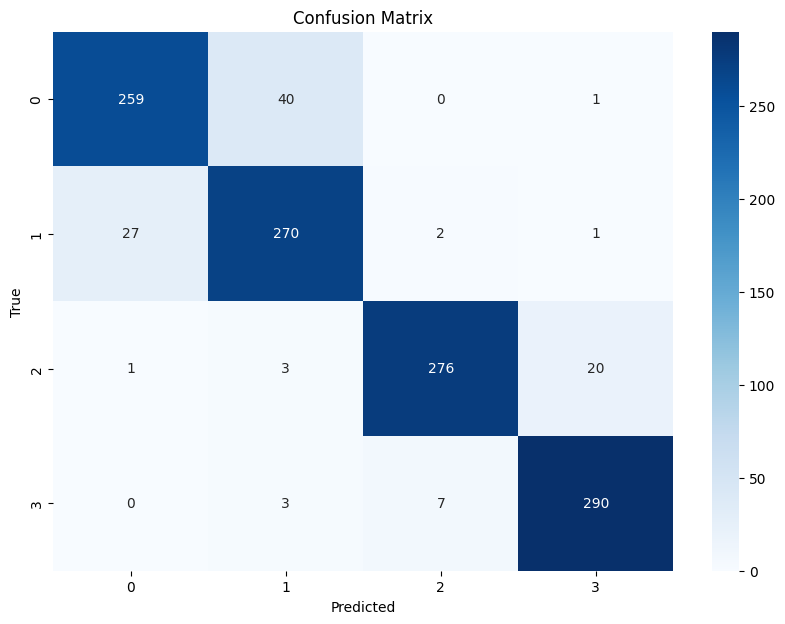

              precision    recall  f1-score   support

     ellisse       0.90      0.86      0.88       300
  rettangolo       0.85      0.90      0.88       300
    segmento       0.97      0.92      0.94       300
       croce       0.93      0.97      0.95       300

    accuracy                           0.91      1200
   macro avg       0.91      0.91      0.91      1200
weighted avg       0.91      0.91      0.91      1200

{'classifier__C': 10, 'classifier__max_iter': 1000, 'classifier__tol': 0.001}


In [29]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

warnings.filterwarnings('ignore')

sc = StandardScaler()
pca = PCA(n_components=ncomponents, whiten=True, random_state=42)
clf = SVC( kernel='rbf', random_state=42)
pipeline = Pipeline(steps=[
    ('scaler',sc),
    ('pca',pca),
    ('classifier', clf)
])

param_grid = {
    'classifier__C': [0.001,0.01,0.1,1,10,100,1000],
    'classifier__max_iter' : [100,500,1000],
    'classifier__tol': [ 1e-3,1e-2,1e-1],
}
gsSVM = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
gsSVM.fit(X_train_e, y_train)

y_pred = gsSVM.predict(X_test_e)
acc_train = accuracy_score(y_train, gsSVM.predict(X_train_e))
acc_test = accuracy_score(y_test, y_pred)
y_pred_test = gsSVM.predict(X_test_e)



labels_nomi = ['ellisse', 'rettangolo', 'segmento', 'croce']    
print(f"Accuracy sul training set: {acc_train:.4f}")
print(f"Accuracy sul test set: {acc_test:.4f}")
labels_classi = [0, 1, 2, 3]
mostra_confusion_matrix(y_test, y_pred, labels=labels_classi)
print(classification_report(y_test, y_pred, target_names=labels_nomi))
print(gsSVM.best_params_)


# Reti Neurali

/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/simonepellegrini/

Accuracy sul training set: 0.9957
Accuracy sul test set: 0.9375


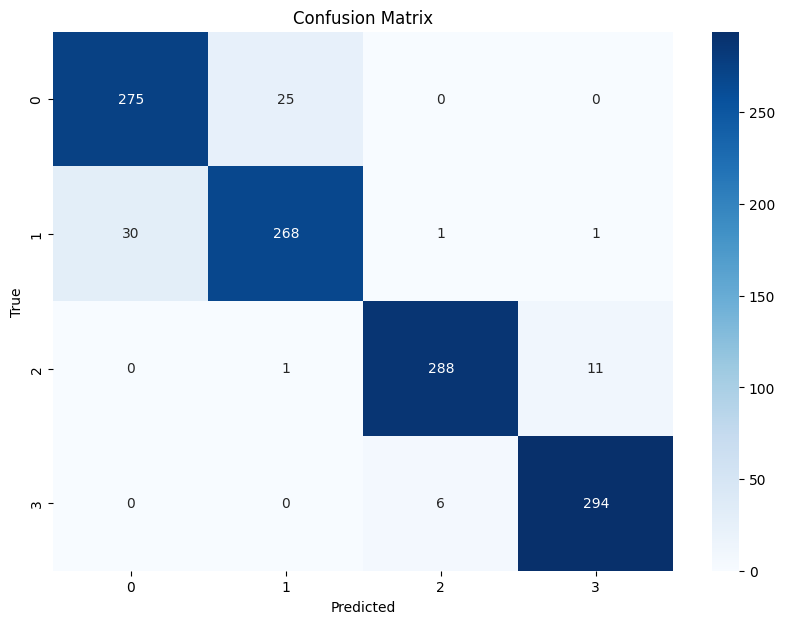

              precision    recall  f1-score   support

     ellisse       0.90      0.92      0.91       300
  rettangolo       0.91      0.89      0.90       300
    segmento       0.98      0.96      0.97       300
       croce       0.96      0.98      0.97       300

    accuracy                           0.94      1200
   macro avg       0.94      0.94      0.94      1200
weighted avg       0.94      0.94      0.94      1200

{'classifier__hidden_layer_sizes': (100, 100), 'classifier__max_iter': 400, 'classifier__tol': 0.001}


In [30]:
pipeline = Pipeline(steps=[
    ('scaler',StandardScaler()),
    ('PCA',PCA(n_components=ncomponents, svd_solver='full', whiten=True)),  
    ('classifier', MLPClassifier())
])

param_grid = {
    'classifier__hidden_layer_sizes': [(10),(50),(100),(100,100),(50,50),(75,75)],
    'classifier__max_iter' : [100,200,300,400,500],
    'classifier__tol': [ 1e-3,1e-2,1e-1]
}
gsMLP = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
gsMLP.fit(X_train_e, y_train)

# Predizioni
y_pred_train = gsMLP.predict(X_train_e)
y_pred_test = gsMLP.predict(X_test_e)

# Metriche generali
acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)

print(f"Accuracy sul training set: {acc_train:.4f}")
print(f"Accuracy sul test set: {acc_test:.4f}")

# ===== PRECISIONE E RECALL PER OGNI CLASSE =====

labels_nomi = ['ellisse', 'rettangolo', 'segmento', 'croce']    
# Nomi delle classi
labels_nomi = ['ellisse', 'rettangolo', 'segmento', 'croce']

mostra_confusion_matrix(y_test, y_pred_test, labels=[0,1,2,3])
print(classification_report(y_test, y_pred_test, target_names=labels_nomi))
print(gsMLP.best_params_)



# Random forest

/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:155: RuntimeWarning: divide by zero encountered in matmul
  X_transformed -= xp.reshape(self.mean_, (1, -1)) @ self.components_.T
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:155: RuntimeWarning: overflow encountered in matmul
  X_transformed -= xp.reshape(sel

Accuracy sul training set: 0.9986
Accuracy sul test set: 0.9367


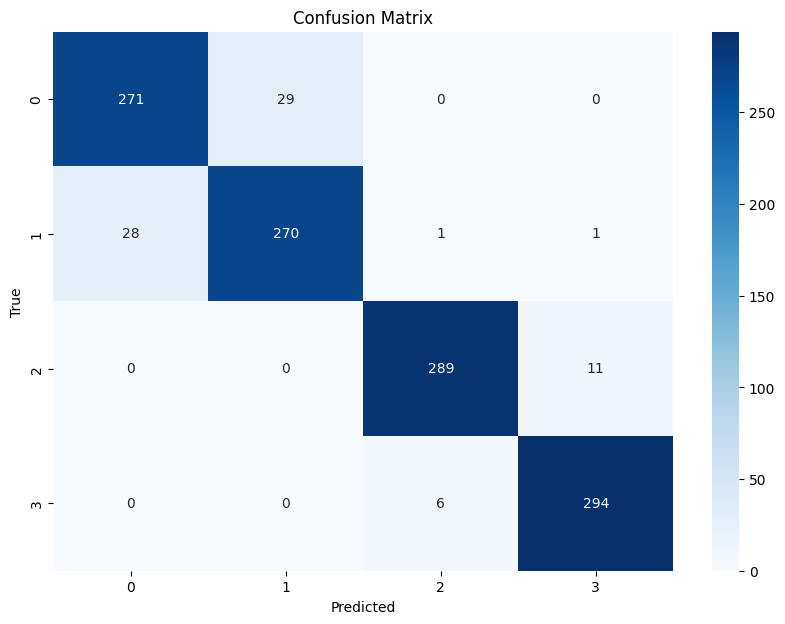

              precision    recall  f1-score   support

     ellisse       0.91      0.90      0.90       300
  rettangolo       0.90      0.90      0.90       300
    segmento       0.98      0.96      0.97       300
       croce       0.96      0.98      0.97       300

    accuracy                           0.94      1200
   macro avg       0.94      0.94      0.94      1200
weighted avg       0.94      0.94      0.94      1200

{'classifier__max_depth': 30, 'classifier__max_features': 'sqrt', 'classifier__max_samples': 0.8, 'classifier__min_samples_split': 4, 'classifier__n_estimators': 175}


In [31]:
from sklearn.ensemble import RandomForestClassifier
import numpy as np

pipeline = Pipeline(steps=[
    ('PCA',PCA(n_components=ncomponents, svd_solver='full', whiten=True)),  
    ('classifier', RandomForestClassifier())
])

param_grid = {
    'classifier__max_depth': [10,20,30,40,50, None],
    'classifier__n_estimators': [75,100,125,150,175],
    'classifier__max_features': ['sqrt'],
    'classifier__max_samples':[0.2,0.5,0.8,1],  #numero di esempi estratti per albero
    'classifier__min_samples_split':[2,4]
}
gsRF = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
gsRF.fit(X_train_e, y_train)

# Predizioni
y_pred_train = gsRF.predict(X_train_e)
y_pred_test = gsRF.predict(X_test_e)

# Metriche generali
acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)

print(f"Accuracy sul training set: {acc_train:.4f}")
print(f"Accuracy sul test set: {acc_test:.4f}")

# ===== PRECISIONE E RECALL PER OGNI CLASSE =====

labels_nomi = ['ellisse', 'rettangolo', 'segmento', 'croce']    
# Nomi delle classi
labels_nomi = ['ellisse', 'rettangolo', 'segmento', 'croce']

mostra_confusion_matrix(y_test, y_pred_test, labels=[0,1,2,3])
print(classification_report(y_test, y_pred_test, target_names=labels_nomi))
print(gsRF.best_params_)



## Logistic Regression

/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # nda

Accuracy sul training set: 0.7343
Accuracy sul test set: 0.7317


/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # nda

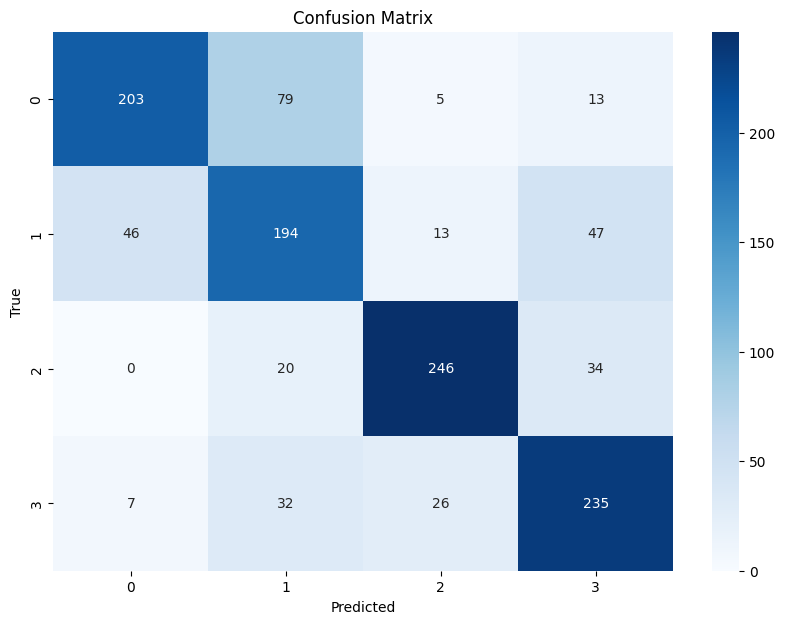

              precision    recall  f1-score   support

     ellisse       0.79      0.68      0.73       300
  rettangolo       0.60      0.65      0.62       300
    segmento       0.85      0.82      0.83       300
       croce       0.71      0.78      0.75       300

    accuracy                           0.73      1200
   macro avg       0.74      0.73      0.73      1200
weighted avg       0.74      0.73      0.73      1200

{'logisticregression__C': 10, 'logisticregression__max_iter': 100, 'logisticregression__multi_class': 'multinomial', 'logisticregression__tol': 0.001}


In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('logisticregression', LogisticRegression(random_state=42,solver='lbfgs'))
])
#definisci la griglia dei parametri per la ricerca
param_grid = {
    'logisticregression__C': [0.001,0.1,1,10,100],
    'logisticregression__tol': [ 1e-3,1e-2,1e-1],
    'logisticregression__max_iter': [100,200,300,400,500,1000],
    'logisticregression__multi_class': ['multinomial'],
}

gsLR = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
gsLR.fit(X_train_a, y_train_a)

# Predizioni
y_pred_train = gsLR.predict(X_train_a)
y_pred_test = gsLR.predict(X_test_a)
acc_train = accuracy_score(y_pred_train,y_train_a)
acc_test = accuracy_score(y_pred_test,y_test_a)

labels_nomi = ['ellisse', 'rettangolo', 'segmento', 'croce']    
print(f"Accuracy sul training set: {acc_train:.4f}")
print(f"Accuracy sul test set: {acc_test:.4f}")
mostra_confusion_matrix(y_test_a, y_pred_test, labels=[0,1,2,3])
print(classification_report(y_test_a, y_pred_test, target_names=labels_nomi))
print(gsLR.best_params_)



# Test di robustezza

In [33]:
def test_model_robustness(model, usa_features_aggregate=False, sfs=None):  
    """
    Testa la robustezza di un modello su dimensione dataset, numero punti e livello rumore.
    
    Args:
        model: modello sklearn già addestrato/ottimizzato
        usa_features_aggregate: se True usa features aggregate, altrimenti coordinate esplicite
        sfs: SequentialFeatureSelector se necessario (per Logistic Regression)
    """
    from sklearn.model_selection import cross_val_score, cross_val_predict
    from sklearn.metrics import accuracy_score, precision_recall_fscore_support
    import numpy as np
    import matplotlib.pyplot as plt
    
    # === TEST DIMENSIONE DATASET ===
    dataset_sizes = [50, 250, 500, 750, 1000, 1500, 2000]
    train_acc_size = []
    val_acc_size = []
    precision_size = {i: [] for i in range(4)}
    recall_size = {i: [] for i in range(4)}
    
    for size in dataset_sizes:
        X, y = genera_campioni(n_shapes=size, n_punti=100, rumore_std_bound=1.0)
        
        if usa_features_aggregate:
            X_processed = ottieni_features_aggregate(X)
            if sfs is not None:
                X_processed = sfs.transform(X_processed)
        else:
            X_processed = calcola_coordinate_relative(X)
        
        model.fit(X_processed, y)
        train_acc_size.append(accuracy_score(y, model.predict(X_processed)))
        
        cv_scores = cross_val_score(model, X_processed, y, cv=3, scoring='accuracy')
        val_acc_size.append(np.mean(cv_scores))
        
        y_pred = cross_val_predict(model, X_processed, y, cv=3)
        precision, recall, _, _ = precision_recall_fscore_support(y, y_pred, average=None)
        
        for classe in range(4):
            precision_size[classe].append(precision[classe])
            recall_size[classe].append(recall[classe])

    # === TEST NUMERO PUNTI ===
    points_range = [50, 100, 150, 200, 250, 300, 400, 500]
    train_acc_points = []
    val_acc_points = []
    precision_points = {i: [] for i in range(4)}
    recall_points = {i: [] for i in range(4)}

    for n_points in points_range:
        X, y = genera_campioni(n_shapes=1000, n_punti=n_points, rumore_std_bound=1.0)
        
        if usa_features_aggregate:
            X_processed = ottieni_features_aggregate(X)
            if sfs is not None:
                X_processed = sfs.transform(X_processed)
        else:
            X_processed = calcola_coordinate_relative(X)
        
        model.fit(X_processed, y)
        train_acc_points.append(accuracy_score(y, model.predict(X_processed)))
        
        cv_scores = cross_val_score(model, X_processed, y, cv=3, scoring='accuracy')
        val_acc_points.append(np.mean(cv_scores))
        
        y_pred = cross_val_predict(model, X_processed, y, cv=3)
        precision, recall, _, _ = precision_recall_fscore_support(y, y_pred, average=None)
        
        for classe in range(4):
            precision_points[classe].append(precision[classe])
            recall_points[classe].append(recall[classe])

    # === TEST LIVELLO RUMORE ===
    noise_levels = [0.1, 0.5, 1.0, 1.6, 2.0, 2.5]
    train_acc_noise = []
    val_acc_noise = []
    precision_noise = {i: [] for i in range(4)}
    recall_noise = {i: [] for i in range(4)}

    for noise in noise_levels:
        X, y = genera_campioni(n_shapes=1000, n_punti=100, rumore_std_bound=noise)
        
        if usa_features_aggregate:
            X_processed = ottieni_features_aggregate(X)
            if sfs is not None:
                X_processed = sfs.transform(X_processed)
        else:
            X_processed = calcola_coordinate_relative(X)
        
        model.fit(X_processed, y)
        train_acc_noise.append(accuracy_score(y, model.predict(X_processed)))
        
        cv_scores = cross_val_score(model, X_processed, y, cv=3, scoring='accuracy')
        val_acc_noise.append(np.mean(cv_scores))
        
        y_pred = cross_val_predict(model, X_processed, y, cv=3)
        precision, recall, _, _ = precision_recall_fscore_support(y, y_pred, average=None)
        
        for classe in range(4):
            precision_noise[classe].append(precision[classe])
            recall_noise[classe].append(recall[classe])

    # === CREAZIONE GRAFICI ===
    labels = ['Ellisse', 'Rettangolo', 'Segmento', 'Croce']
    colors = ['blue', 'green', 'orange', 'red']

    fig, axes = plt.subplots(3, 3, figsize=(18, 16))

    # PRIMA RIGA: ACCURACY
    axes[0,0].plot(dataset_sizes, train_acc_size, 'b-o', label='Training Accuracy', linewidth=2)
    axes[0,0].plot(dataset_sizes, val_acc_size, 'g-o', label='Validation Accuracy', linewidth=2)
    axes[0,0].set_xlabel('Numero di forme per classe')
    axes[0,0].set_ylabel('Accuracy')
    axes[0,0].set_title('Robustezza Modello - Dimensione Dataset (Accuracy)')
    axes[0,0].legend()
    axes[0,0].grid(True, alpha=0.3)
    axes[0,0].set_ylim(0.5, 1.05)

    axes[0,1].plot(points_range, train_acc_points, 'b-o', label='Training Accuracy', linewidth=2)
    axes[0,1].plot(points_range, val_acc_points, 'g-o', label='Validation Accuracy', linewidth=2)
    axes[0,1].set_xlabel('Numero di punti per forma')
    axes[0,1].set_ylabel('Accuracy')
    axes[0,1].set_title('Robustezza Modello - Numero di Punti (Accuracy)')
    axes[0,1].legend()
    axes[0,1].grid(True, alpha=0.3)
    axes[0,1].set_ylim(0.5, 1.05)

    axes[0,2].plot(noise_levels, train_acc_noise, 'b-o', label='Training Accuracy', linewidth=2)
    axes[0,2].plot(noise_levels, val_acc_noise, 'g-o', label='Validation Accuracy', linewidth=2)
    axes[0,2].set_xlabel('Livello di rumore (std)')
    axes[0,2].set_ylabel('Accuracy')
    axes[0,2].set_title('Robustezza Modello - Livello di Rumore (Accuracy)')
    axes[0,2].legend()
    axes[0,2].grid(True, alpha=0.3)
    axes[0,2].set_ylim(0.5, 1.05)

    # SECONDA RIGA: PRECISION
    for classe in range(4):
        axes[1,0].plot(dataset_sizes, precision_size[classe], 'o-', 
                       label=labels[classe], color=colors[classe], linewidth=2)
        axes[1,1].plot(points_range, precision_points[classe], 'o-', 
                       label=labels[classe], color=colors[classe], linewidth=2)
        axes[1,2].plot(noise_levels, precision_noise[classe], 'o-', 
                       label=labels[classe], color=colors[classe], linewidth=2)

    axes[1,0].set_xlabel('Numero di forme per classe')
    axes[1,0].set_ylabel('Precision')
    axes[1,0].set_title('Robustezza Modello - Dimensione Dataset (Precision)')
    axes[1,0].legend()
    axes[1,0].grid(True, alpha=0.3)
    axes[1,0].set_ylim(0.5, 1.05)

    axes[1,1].set_xlabel('Numero di punti per forma')
    axes[1,1].set_ylabel('Precision')
    axes[1,1].set_title('Robustezza Modello - Numero di Punti (Precision)')
    axes[1,1].legend()
    axes[1,1].grid(True, alpha=0.3)
    axes[1,1].set_ylim(0.5, 1.05)

    axes[1,2].set_xlabel('Livello di rumore (std)')
    axes[1,2].set_ylabel('Precision')
    axes[1,2].set_title('Robustezza Modello - Livello di Rumore (Precision)')
    axes[1,2].legend()
    axes[1,2].grid(True, alpha=0.3)
    axes[1,2].set_ylim(0.5, 1.05)

    # TERZA RIGA: RECALL
    for classe in range(4):
        axes[2,0].plot(dataset_sizes, recall_size[classe], 'o-', 
                       label=labels[classe], color=colors[classe], linewidth=2)
        axes[2,1].plot(points_range, recall_points[classe], 'o-', 
                       label=labels[classe], color=colors[classe], linewidth=2)
        axes[2,2].plot(noise_levels, recall_noise[classe], 'o-', 
                       label=labels[classe], color=colors[classe], linewidth=2)

    axes[2,0].set_xlabel('Numero di forme per classe')
    axes[2,0].set_ylabel('Recall')
    axes[2,0].set_title('Robustezza Modello - Dimensione Dataset (Recall)')
    axes[2,0].legend()
    axes[2,0].grid(True, alpha=0.3)
    axes[2,0].set_ylim(0.5, 1.05)

    axes[2,1].set_xlabel('Numero di punti per forma')
    axes[2,1].set_ylabel('Recall')
    axes[2,1].set_title('Robustezza Modello - Numero di Punti (Recall)')
    axes[2,1].legend()
    axes[2,1].grid(True, alpha=0.3)
    axes[2,1].set_ylim(0.5, 1.05)

    axes[2,2].set_xlabel('Livello di rumore (std)')
    axes[2,2].set_ylabel('Recall')
    axes[2,2].set_title('Robustezza Modello - Livello di Rumore (Recall)')
    axes[2,2].legend()
    axes[2,2].grid(True, alpha=0.3)
    axes[2,2].set_ylim(0.5, 1.05)

    plt.suptitle('Test di Robustezza - Classificazione Multi-classe', fontsize=14)
    plt.tight_layout()
    plt.show()


# SVM

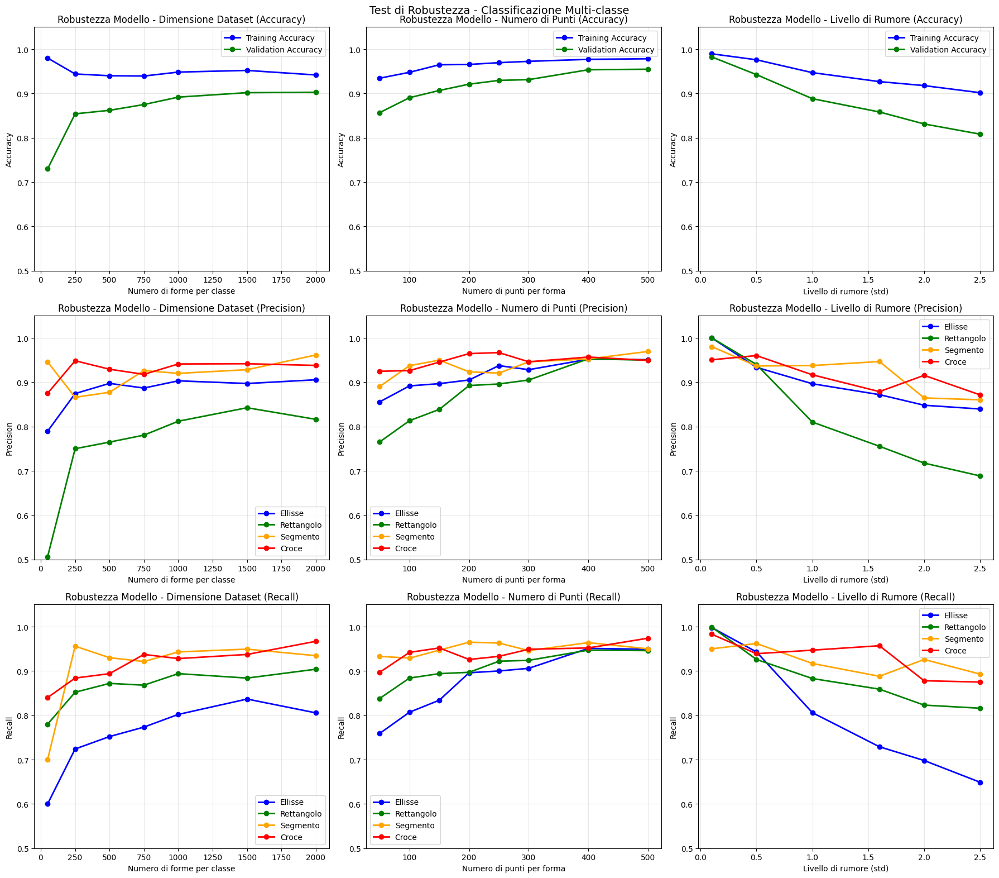

In [34]:
test_model_robustness(gsSVM.best_estimator_)

# RandomForest

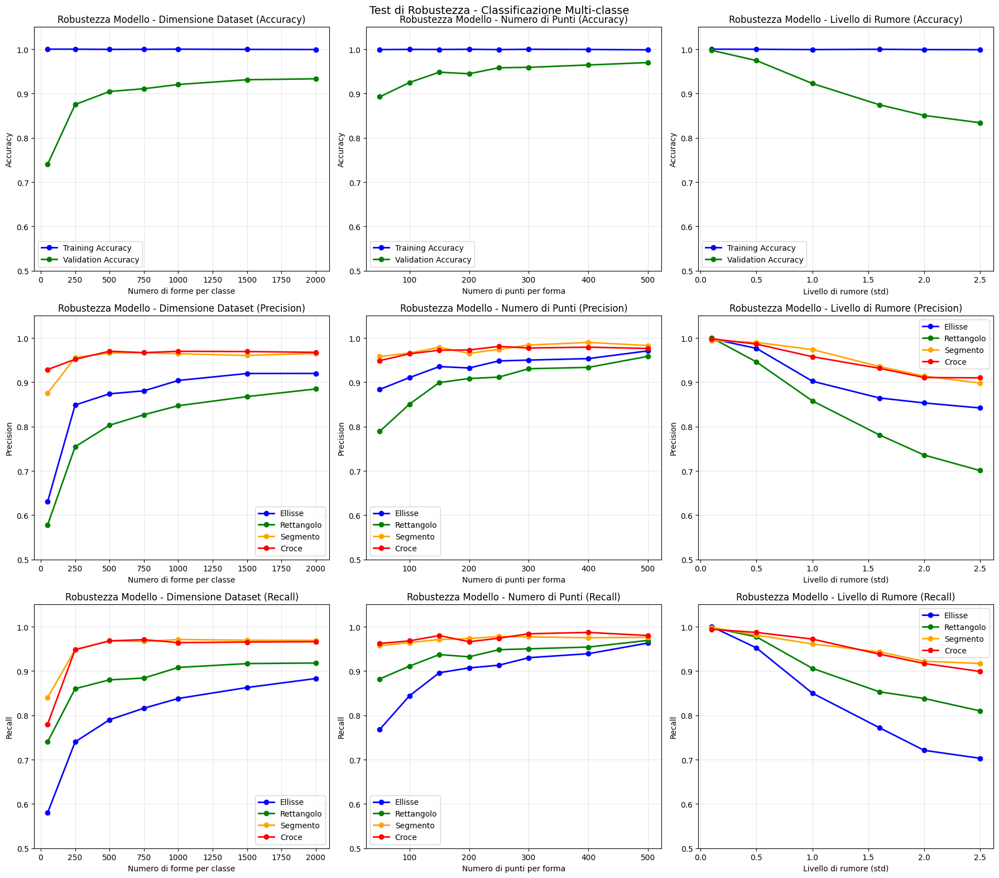

In [35]:
test_model_robustness(gsRF.best_estimator_)

# Reti neurali

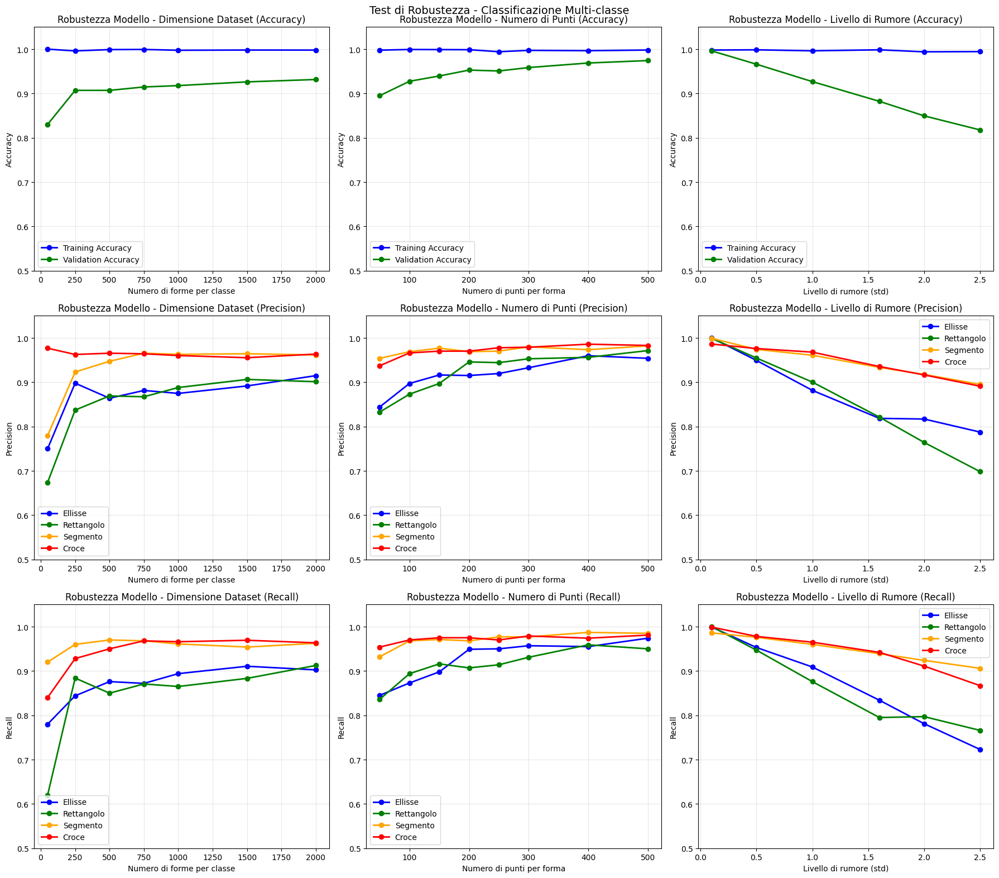

In [36]:
test_model_robustness(gsMLP.best_estimator_)

# LogReg

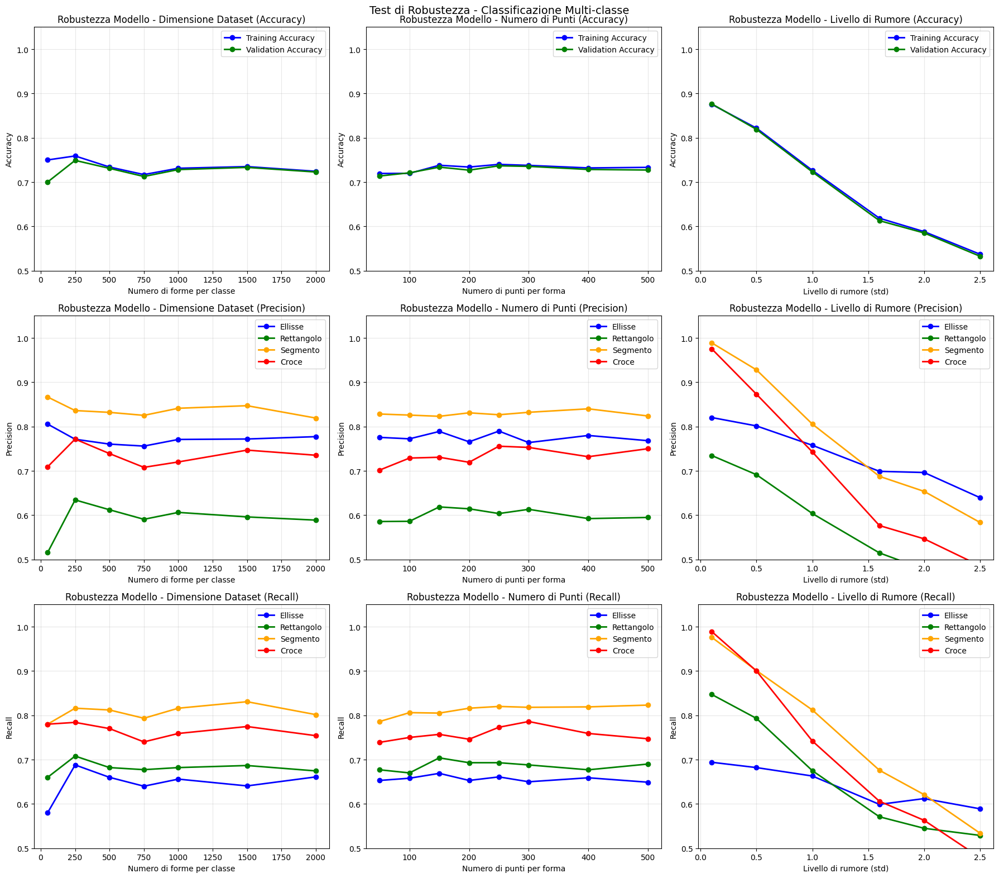

In [37]:
test_model_robustness(gsLR.best_estimator_,True,sfs=sfs)

# Classificazione Binaria

In questa sezione addestriamo modelli per la classificazione di figure con area (rettangoli/ellissi) da quelle senza area (segmenti/croci). Utilizziamo metodologie simili a quelle viste nella parte precedente ma adattate a una classificazione binaria. In particolare osserviamo come il problema rilassato possa essere risolto con ottimi risultati anche con modelli più semplici (ovvero con meno features) e con risultati anche migliori rispetto alla fase precedente.


## genera campioni binari

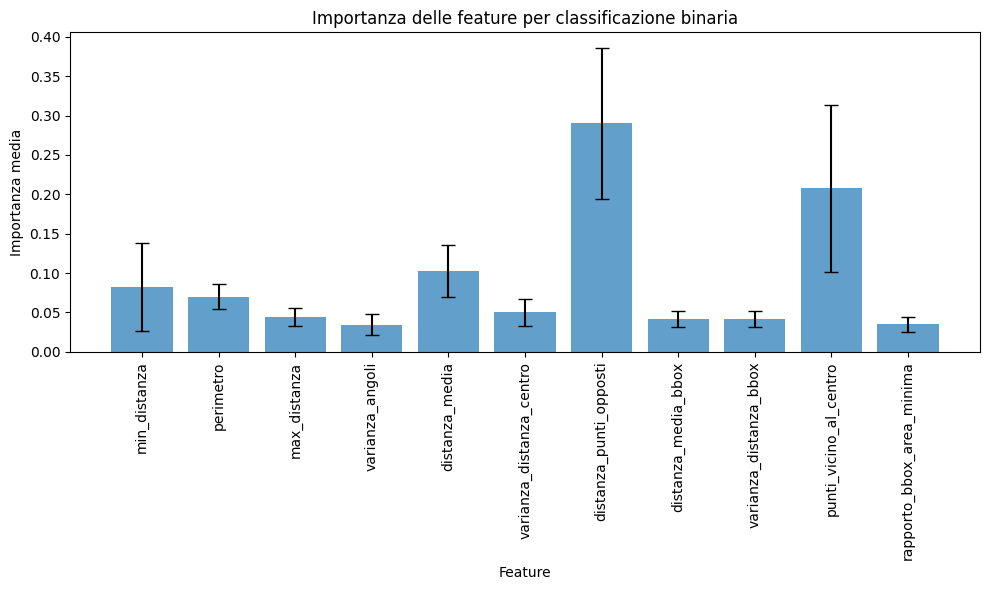

In [38]:
X, y_orig = genera_campioni(n_shapes=1000, n_punti=100, rumore_std_bound=1)
y_bin = np.where((y_orig == 0) | (y_orig == 1), 1, 0)  # 1 = area positiva, 0 = area nulla
#print(y_bin)

## Features selection

# Estrai features aggregate
X_f = ottieni_features_aggregate(X)

# Split del dataset
X_train, X_test, y_train, y_test = train_test_split(X_f, y_bin, test_size=0.3, stratify=y_bin, random_state=42)

# Costruzione pipeline con ExtraTrees
forest = ExtraTreesClassifier(n_estimators=250, random_state=0)
pipeline = Pipeline([
    ('preproc', StandardScaler()),
    ('clf', forest)
])

# Fit del modello
pipeline.fit(X_train, y_train)

# Importanza delle feature
importances = pipeline.named_steps['clf'].feature_importances_
feature_importances_per_tree = np.array([tree.feature_importances_ for tree in forest.estimators_])
importances_df = pd.DataFrame(feature_importances_per_tree, columns=X_f.columns)

# Statistiche (media e std)
dd = importances_df.agg(['mean', 'std']).T.reset_index()
dd.columns = ['Feature', 'Mean', 'Std']

# Grafico importanza
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(dd['Feature'], dd['Mean'], yerr=dd['Std'], alpha=0.7, capsize=5)
ax.set_title('Importanza delle feature per classificazione binaria')
ax.set_ylabel('Importanza media')
ax.set_xlabel('Feature')
ax.set_xticklabels(dd['Feature'], rotation=90)
fig.tight_layout()
plt.show()

In [39]:
# Usa le stesse X_train e y_train definiti nel problema binario
estimator = ExtraTreesClassifier(n_estimators=250, random_state=42)

# Selezione sequenziale delle 3 migliori feature (con validazione incrociata)
sfs = SequentialFeatureSelector(
    estimator,
    n_features_to_select=3,
    direction='backward',  # parte da tutte e rimuove le meno utili
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Fit sul training set binario
sfs.fit(X_train, y_train)

# Ottieni solo le feature selezionate
X_selected_forward = sfs.transform(X_train)
selected_features = X_train.columns[sfs.get_support()]

print("Feature selezionate per il problema binario:")
print(selected_features)


Feature selezionate per il problema binario:
Index(['perimetro', 'distanza_media', 'distanza_punti_opposti'], dtype='object')


### valutazione della features selection sulle prestazioni dei vari modelli

In [40]:
# Ottieni feature aggregate
X_f = ottieni_features_aggregate(X)

# Split dei dati
X_train, X_test, y_train, y_test = train_test_split(X_f, y_bin, test_size=0.3, stratify=y_bin, random_state=42)

# Applica la stessa selezione già addestrata (sfs)
X_train_selected = sfs.transform(X_train)
X_test_selected = sfs.transform(X_test)

# ===========================
# Modelli SENZA selection
# ===========================
acc_senza_selection = {}

rf = RandomForestClassifier(random_state=42, n_estimators=100)
rf.fit(X_train, y_train)
acc_senza_selection['Random Forest'] = accuracy_score(y_test, rf.predict(X_test))

lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(solver='saga', random_state=42, max_iter=5000))
])
lr.fit(X_train, y_train)
acc_senza_selection['Logistic Regression'] = accuracy_score(y_test, lr.predict(X_test))

svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', random_state=42))
])
svm.fit(X_train, y_train)
acc_senza_selection['SVM'] = accuracy_score(y_test, svm.predict(X_test))

mlp = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', MLPClassifier(random_state=42))
])
mlp.fit(X_train, y_train)
acc_senza_selection['MLP'] = accuracy_score(y_test, mlp.predict(X_test))

# ===========================
# Modelli CON selection
# ===========================
acc_con_selection = {}

rf_sel = RandomForestClassifier(random_state=42, n_estimators=100)
rf_sel.fit(X_train_selected, y_train)
acc_con_selection['Random Forest'] = accuracy_score(y_test, rf_sel.predict(X_test_selected))

lr_sel = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(solver='saga', max_iter=5000, random_state=42))
])
lr_sel.fit(X_train_selected, y_train)
acc_con_selection['Logistic Regression'] = accuracy_score(y_test, lr_sel.predict(X_test_selected))

svm_sel = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='linear', random_state=42))
])
svm_sel.fit(X_train_selected, y_train)
acc_con_selection['SVM'] = accuracy_score(y_test, svm_sel.predict(X_test_selected))

mlp_sel = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', MLPClassifier(random_state=42))
])
mlp_sel.fit(X_train_selected, y_train)
acc_con_selection['MLP'] = accuracy_score(y_test, mlp_sel.predict(X_test_selected))

# ===========================
# Confronto finale
# ===========================
df_confronto = pd.DataFrame({
    'Modello': acc_senza_selection.keys(),
    'Accuracy SENZA SELECTION': list(acc_senza_selection.values()),
    'Accuracy CON SELECTION': list(acc_con_selection.values())
})

print(df_confronto)


               Modello  Accuracy SENZA SELECTION  Accuracy CON SELECTION
0        Random Forest                  0.919167                0.910833
1  Logistic Regression                  0.913333                0.909167
2                  SVM                  0.920833                0.910833
3                  MLP                  0.925833                0.922500


## Features extration

In [41]:
# Parametri PCA
ncomponents = 5
pca = PCA(n_components=ncomponents, whiten=True, random_state=42)

# Rietichettatura binaria
X, y_orig = genera_campioni(n_shapes=1000, n_punti=100, rumore_std_bound=rumore_const)
y_bin = np.where((y_orig == 0) | (y_orig == 1), 1, 0)  # 1 = area, 0 = no area

# Coordinate relative al centroide
X_f = calcola_coordinate_relative(X)

# Split dei dati
X_train, X_test, y_train, y_test = train_test_split(X_f, y_bin, test_size=0.3, stratify=y_bin, random_state=42)

# PCA pipeline
pipeline_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', pca)
])
pipeline_pca.fit(X_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('pca', PCA(n_components=5, random_state=42, whiten=True))])


### confronto modelli con e senza PCA sulla classificazione binaria

In [42]:
# Coordinate relative
X_esplicito = calcola_coordinate_relative(X)
X_train, X_test, y_train, y_test = train_test_split(X_esplicito, y_bin, test_size=0.3, stratify=y_bin, random_state=42)

# ========== Modelli SENZA PCA ==========
acc_senza_pca = {}

# Random Forest
rf = RandomForestClassifier(random_state=42, n_estimators=100)
rf.fit(X_train, y_train)
acc_senza_pca['Random Forest'] = accuracy_score(y_test, rf.predict(X_test))

# Logistic Regression
lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(solver='saga', max_iter=10000, random_state=42))
])
lr.fit(X_train, y_train)
acc_senza_pca['Logistic Regression'] = accuracy_score(y_test, lr.predict(X_test))

# SVM
svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', random_state=42))
])
svm.fit(X_train, y_train)
acc_senza_pca['SVM'] = accuracy_score(y_test, svm.predict(X_test))

# MLP
mlp = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', MLPClassifier(random_state=42))
])
mlp.fit(X_train, y_train)
acc_senza_pca['MLP'] = accuracy_score(y_test, mlp.predict(X_test))

# ========== Modelli CON PCA ==========
#ncomponents = 10
pca = PCA(n_components=ncomponents, whiten=True, random_state=42)

# Standardizzazione
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# PCA transform
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Accuracy con PCA
acc_con_pca = {}

# Random Forest
rf_pca = RandomForestClassifier(random_state=42)
rf_pca.fit(X_train_pca, y_train)
acc_con_pca['Random Forest'] = accuracy_score(y_test, rf_pca.predict(X_test_pca))

# Logistic Regression
lr_pca = LogisticRegression(solver='saga', max_iter=10000, random_state=42)
lr_pca.fit(X_train_pca, y_train)
acc_con_pca['Logistic Regression'] = accuracy_score(y_test, lr_pca.predict(X_test_pca))

# SVM
svm_pca = SVC(kernel='rbf', random_state=42)
svm_pca.fit(X_train_pca, y_train)
acc_con_pca['SVM'] = accuracy_score(y_test, svm_pca.predict(X_test_pca))

# MLP
mlp_pca = MLPClassifier(random_state=42)
mlp_pca.fit(X_train_pca, y_train)
acc_con_pca['MLP'] = accuracy_score(y_test, mlp_pca.predict(X_test_pca))

# ========== Confronto finale ==========
df_confronto = pd.DataFrame({
    'Modello': acc_senza_pca.keys(),
    'Accuracy SENZA PCA': list(acc_senza_pca.values()),
    'Accuracy CON PCA': list(acc_con_pca.values())
})

print(df_confronto)


               Modello  Accuracy SENZA PCA  Accuracy CON PCA
0        Random Forest            0.972500          0.987500
1  Logistic Regression            0.523333          0.500833
2                  SVM            0.985000          0.985833
3                  MLP            0.993333          0.989167


## Model selection

In [43]:
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

def mostra_confusion_e_roc(model, X_test, y_test, class_names=['No Area', 'Area']):
    """
    Mostra confusion matrix e curva ROC affiancati
    
    Parameters:
    - model: modello addestrato (con predict e predict_proba)
    - X_test: dati di test
    - y_test: etichette vere di test
    - class_names: nomi delle classi per la confusion matrix
    """
    
    # Calcola predizioni e probabilità
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]  # probabilità classe 1
    
    # Calcola metriche
    acc = accuracy_score(y_test, y_pred)
    fpr, tpr, thresholds = roc_curve(y_test, y_prob, pos_label=1)
    roc_auc = auc(fpr, tpr)
    
    # Crea subplot
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names,
                yticklabels=class_names,
                ax=axes[0])
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("True")
    axes[0].set_title(f"Confusion Matrix\nAccuracy: {acc:.3f}")
    
    # ROC Curve
    axes[1].plot(fpr, tpr, color='darkorange', lw=2, 
                label=f'ROC curve (AUC = {roc_auc:.3f})')
    axes[1].fill_between(fpr, 0, tpr, alpha=0.2, color='darkorange')
    axes[1].plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--',
                label='Random classifier')
    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_ylim([0.0, 1.05])
    axes[1].set_xlabel('False Positive Rate')
    axes[1].set_ylabel('True Positive Rate')
    axes[1].set_title('ROC Curve')
    axes[1].legend(loc="lower right")
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

    

# Utilizzo:
# mostra_confusion_e_roc(gsSVM.best_estimator_, X_test_e, y_test_e)

# Etichette binarie: 0 = no area (segmento, croce), 1 = area (ellisse, rettangolo)
labels_classi_binaria = [0, 1]


# Genera dati e crea etichette binarie (1 = area, 0 = no area)
X, y_orig = genera_campioni(n_shapes=1000, n_punti=100, rumore_std_bound=rumore_const)
y_bin = np.where((y_orig == 0) | (y_orig == 1), 1, 0)

# Estrai rappresentazioni
X_e = calcola_coordinate_relative(X)       # Esplicita: coordinate relative
X_a = ottieni_features_aggregate(X)        # Aggregata: perimetro, distanza, ecc.
X_a = sfs.transform(X_a)
# Split dei dati
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_e, y_bin, test_size=0.3, stratify=y_bin, random_state=42)
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(X_a, y_bin, test_size=0.3, stratify=y_bin, random_state=42)

### SVM

/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.

Accuracy sul training set: 0.2461
Accuracy sul test set: 0.9925
F1-score sul test set: 0.9925


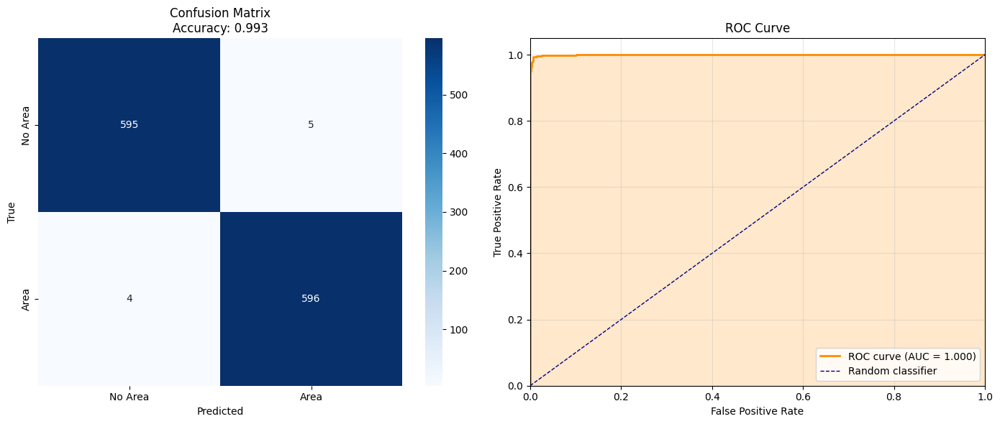

              precision    recall  f1-score   support

     No Area       0.99      0.99      0.99       600
        Area       0.99      0.99      0.99       600

    accuracy                           0.99      1200
   macro avg       0.99      0.99      0.99      1200
weighted avg       0.99      0.99      0.99      1200

Miglior parametro C trovato: {'classifier__C': 100, 'classifier__max_iter': 500}


In [44]:

sc = StandardScaler()

# SVM con RBF kernel
clf = SVC(kernel='rbf', gamma='scale', probability=True, random_state=42)

# Pipeline: scaler → PCA → SVM
pipeline = Pipeline(steps=[
    ('scaler', sc),
    ('pca', pca),
    ('classifier', clf)
])

# Griglia per ricerca iperparametro C
param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'classifier__max_iter':[10,50,100,200,500]
}

# Grid Search CV (5-fold)
gsSVM = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
gsSVM.fit(X_train_e, y_train_e)
y_pred_test = gsSVM.predict(X_test_e)
# Predizioni
acc_train = accuracy_score(y_train_e, y_pred_train)
acc_test = accuracy_score(y_test_e, y_pred_test)
f1_test = f1_score(y_test_e, y_pred_test, average="binary")  # binario

print(f"Accuracy sul training set: {acc_train:.4f}")
print(f"Accuracy sul test set: {acc_test:.4f}")
print(f"F1-score sul test set: {f1_test:.4f}")

mostra_confusion_e_roc(gsSVM.best_estimator_,X_test_e,y_test_e,class_names=['No Area', 'Area'])
print(classification_report(y_test_e, y_pred_test, target_names=['No Area', 'Area']))
print("Miglior parametro C trovato:", gsSVM.best_params_)


### Random Forest

/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.

Accuracy sul training set: 0.9996
Accuracy sul test set: 0.9908
F1-score sul test set: 0.9909


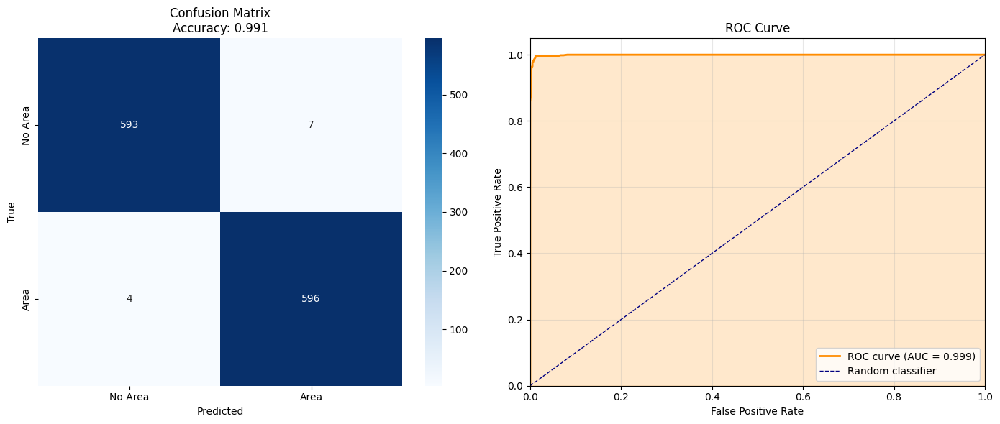

              precision    recall  f1-score   support

     No Area       0.99      0.99      0.99       600
        Area       0.99      0.99      0.99       600

    accuracy                           0.99      1200
   macro avg       0.99      0.99      0.99      1200
weighted avg       0.99      0.99      0.99      1200

Migliori iperparametri: {'classifier__max_depth': 20, 'classifier__max_features': 'sqrt', 'classifier__max_samples': 0.8, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}


In [45]:
# Pipeline: PCA + Random Forest
pipeline = Pipeline(steps=[
    ('scaler',StandardScaler()),
    ('PCA', pca),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

# Griglia iperparametri
param_grid = {
    'classifier__max_depth': [10,20,30,40,50, None],
    'classifier__n_estimators': [75,100,125,150,175],
    'classifier__max_features': ['sqrt'],
    'classifier__max_samples':[0.2,0.5,0.8,1],  #numero di esempi estratti per albero
    'classifier__min_samples_split':[2,4]
}
# GridSearchCV
gsRF = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
gsRF.fit(X_train_e, y_train_e)

# Predizioni
y_pred_train = gsRF.predict(X_train_e)
y_pred_test = gsRF.predict(X_test_e)

# Metriche
acc_train = accuracy_score(y_train_e, y_pred_train)
acc_test = accuracy_score(y_test_e, y_pred_test)
f1_test = f1_score(y_test_e, y_pred_test, average="binary")  # binario

print(f"Accuracy sul training set: {acc_train:.4f}")
print(f"Accuracy sul test set: {acc_test:.4f}")
print(f"F1-score sul test set: {f1_test:.4f}")

# Confusion matrix & classification report (binario)
mostra_confusion_e_roc(gsRF.best_estimator_,X_test_e,y_test_e,class_names=['No Area', 'Area'])
print(classification_report(y_test_e, y_pred_test, target_names=['No Area', 'Area']))

# Parametri ottimali trovati
print("Migliori iperparametri:", gsRF.best_params_)

### Logistic regretion

(2800, 3)


/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1237: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, binary problems will be fit as proper binary  logistic regression models (as if multi_class='ovr' were set). Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1237: FutureWarning: '

Accuracy sul training set: 0.8982
Accuracy sul test set: 0.8933
F1-score sul test set: 0.8912


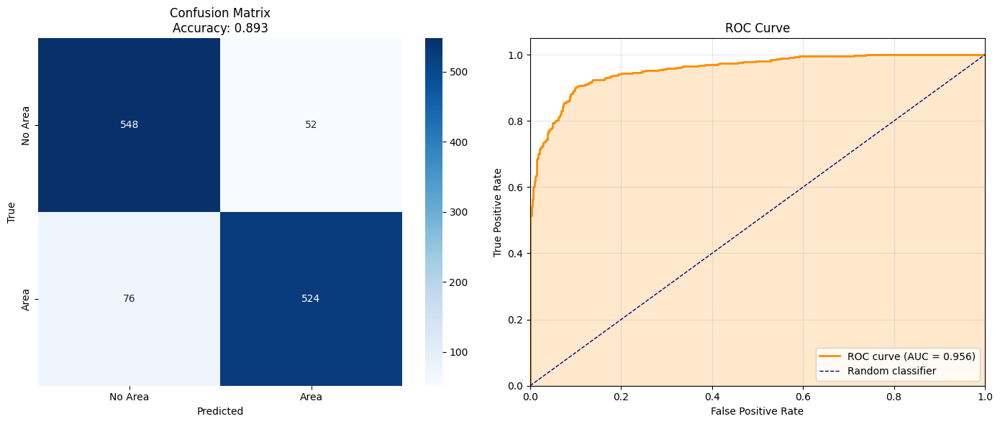

              precision    recall  f1-score   support

     No Area       0.88      0.91      0.90       600
        Area       0.91      0.87      0.89       600

    accuracy                           0.89      1200
   macro avg       0.89      0.89      0.89      1200
weighted avg       0.89      0.89      0.89      1200

Migliori iperparametri Logistic Regression: {'logisticregression__C': 10, 'logisticregression__max_iter': 100, 'logisticregression__multi_class': 'multinomial', 'logisticregression__tol': 0.001}


In [46]:

pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('logisticregression', LogisticRegression(random_state=42, solver='saga'))
])

# Grid più leggera
param_grid = {
    'logisticregression__C': [0.001,0.1,1,10,100],
    'logisticregression__tol': [ 1e-3,1e-2,1e-1],
    'logisticregression__max_iter': [100,200,300,400,500,1000],
    'logisticregression__multi_class': ['multinomial'],
}
print(X_train_a.shape)
gsLR = GridSearchCV(pipeline, param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
gsLR.fit(X_train_a, y_train_a)

# Predizioni
y_pred_train = gsLR.predict(X_train_a)
y_pred_test = gsLR.predict(X_test_a)

print(f"Accuracy sul training set: {accuracy_score(y_train_a, y_pred_train):.4f}")
print(f"Accuracy sul test set: {accuracy_score(y_test_a, y_pred_test):.4f}")
print(f"F1-score sul test set: {f1_score(y_test_a, y_pred_test, average='binary'):.4f}")

thrLR = mostra_confusion_e_roc(gsLR.best_estimator_,X_test_a,y_test_a,class_names=['No Area', 'Area'])
print(classification_report(y_test_a, y_pred_test, target_names=['No Area', 'Area']))

print("Migliori iperparametri Logistic Regression:", gsLR.best_params_)

# Reti Neurali

/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.

Accuracy sul training set: 0.9957
Accuracy sul test set: 0.9917
F1-score sul test set: 0.9917


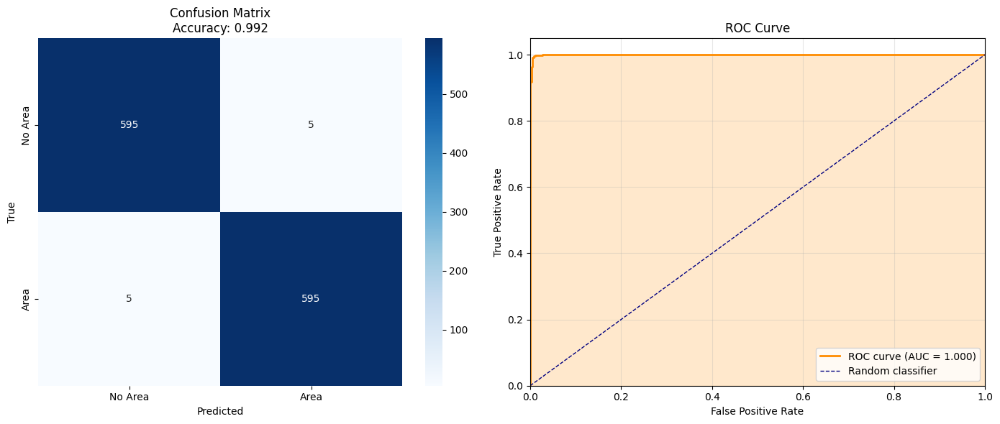

              precision    recall  f1-score   support

     No Area       0.99      0.99      0.99       600
        Area       0.99      0.99      0.99       600

    accuracy                           0.99      1200
   macro avg       0.99      0.99      0.99      1200
weighted avg       0.99      0.99      0.99      1200

Miglior hidden_layer_sizes: 100


In [47]:
# Pipeline: scaler + MLP
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca',pca),
    ('mlp', MLPClassifier(random_state=42, max_iter=100))
])

# Grid di architetture leggere (fino a 3 hidden layer)
param_grid = {
    'mlp__hidden_layer_sizes': [(10),(50),(100),(100,100),(50,50),(75,75)],
    'mlp__max_iter' : [100,200,300,400,500],
    'mlp__tol': [ 1e-3,1e-2,1e-1]
}
gsMLP = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
gsMLP.fit(X_train_e, y_train_e)

# Predizioni
y_pred_train = gsMLP.predict(X_train_e)
y_pred_test = gsMLP.predict(X_test_e)

# Metriche
print(f"Accuracy sul training set: {accuracy_score(y_train_e, y_pred_train):.4f}")
print(f"Accuracy sul test set: {accuracy_score(y_test_e, y_pred_test):.4f}")
print(f"F1-score sul test set: {f1_score(y_test_e, y_pred_test, average='binary'):.4f}")

# Confusion matrix + report
mostra_confusion_e_roc(gsMLP.best_estimator_,X_test_e,y_test_e,class_names=['No Area', 'Area'])
print(classification_report(y_test_e, y_pred_test, target_names=["No Area", "Area"]))

# Miglior architettura trovata
print("Miglior hidden_layer_sizes:", gsMLP.best_params_['mlp__hidden_layer_sizes'])

# Test di robustezza

In [48]:
def test_robustezza_binaria(model, usa_features_aggregate=False, sfs=None):
    """
    Testa robustezza modello su dimensione dataset, numero punti e livello rumore.
    
    Args:
        model: modello sklearn già addestrato
        usa_features_aggregate: se True usa features aggregate, altrimenti coordinate esplicite
        sfs: SequentialFeatureSelector se necessario (per Logistic Regression)
    """
    from sklearn.model_selection import cross_val_score, cross_val_predict
    from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_curve
    import numpy as np
    import matplotlib.pyplot as plt
    
    # Test dimensione dataset
    dataset_sizes = [50, 250, 500, 750, 1000, 1500, 2000]
    train_acc_size = []
    val_acc_size = []
    precision_size = {i: [] for i in range(2)}  # 2 classi binarie
    recall_size = {i: [] for i in range(2)}

    for size in dataset_sizes:
        X, y_orig = genera_campioni(n_shapes=size, n_punti=100, rumore_std_bound=1.0)
        y_bin = np.where((y_orig == 0) | (y_orig == 1), 1, 0)
        
        if usa_features_aggregate:
            X_processed = ottieni_features_aggregate(X)
            if sfs is not None:
                X_processed = sfs.transform(X_processed)
        else:
            X_processed = calcola_coordinate_relative(X)
        
        model.fit(X_processed, y_bin)
        train_acc_size.append(accuracy_score(y_bin, model.predict(X_processed)))
        
        cv_scores = cross_val_score(model, X_processed, y_bin, cv=3, scoring='accuracy')
        val_acc_size.append(np.mean(cv_scores))
        
        y_pred = cross_val_predict(model, X_processed, y_bin, cv=3)
        precision, recall, _, _ = precision_recall_fscore_support(y_bin, y_pred, average=None)
        
        for classe in range(2):
            precision_size[classe].append(precision[classe])
            recall_size[classe].append(recall[classe])

    # Test numero punti
    points_range = [50, 100, 150, 200, 250, 300, 400, 500]
    train_acc_points = []
    val_acc_points = []
    precision_points = {i: [] for i in range(2)}
    recall_points = {i: [] for i in range(2)}

    for n_points in points_range:
        X, y_orig = genera_campioni(n_shapes=1000, n_punti=n_points, rumore_std_bound=1.0)
        y_bin = np.where((y_orig == 0) | (y_orig == 1), 1, 0)
        
        if usa_features_aggregate:
            X_processed = ottieni_features_aggregate(X)
            if sfs is not None:
                X_processed = sfs.transform(X_processed)
        else:
            X_processed = calcola_coordinate_relative(X)
        
        model.fit(X_processed, y_bin)
        train_acc_points.append(accuracy_score(y_bin, model.predict(X_processed)))
        
        cv_scores = cross_val_score(model, X_processed, y_bin, cv=3, scoring='accuracy')
        val_acc_points.append(np.mean(cv_scores))
        
        y_pred = cross_val_predict(model, X_processed, y_bin, cv=3)
        precision, recall, _, _ = precision_recall_fscore_support(y_bin, y_pred, average=None)
        
        for classe in range(2):
            precision_points[classe].append(precision[classe])
            recall_points[classe].append(recall[classe])

    # Test livello rumore
    noise_levels = [0.1, 0.5, 1.0, 1.6, 2.0, 2.5]
    train_acc_noise = []
    val_acc_noise = []
    precision_noise = {i: [] for i in range(2)}
    recall_noise = {i: [] for i in range(2)}

    for noise in noise_levels:
        X, y_orig = genera_campioni(n_shapes=1000, n_punti=100, rumore_std_bound=noise)
        y_bin = np.where((y_orig == 0) | (y_orig == 1), 1, 0)
        
        if usa_features_aggregate:
            X_processed = ottieni_features_aggregate(X)
            if sfs is not None:
                X_processed = sfs.transform(X_processed)
        else:
            X_processed = calcola_coordinate_relative(X)
        
        model.fit(X_processed, y_bin)
        train_acc_noise.append(accuracy_score(y_bin, model.predict(X_processed)))
        
        cv_scores = cross_val_score(model, X_processed, y_bin, cv=3, scoring='accuracy')
        val_acc_noise.append(np.mean(cv_scores))
        
        y_pred = cross_val_predict(model, X_processed, y_bin, cv=3)
        precision, recall, _, _ = precision_recall_fscore_support(y_bin, y_pred, average=None)
        
        for classe in range(2):
            precision_noise[classe].append(precision[classe])
            recall_noise[classe].append(recall[classe])

    # Grafici
    labels = ['Area Nulla', 'Area Positiva']
    colors = ['orange', 'blue']

    fig, axes = plt.subplots(3, 3, figsize=(18, 16))

    # PRIMA RIGA: ACCURACY
    axes[0,0].plot(dataset_sizes, train_acc_size, 'b-o', label='Training Accuracy', linewidth=2)
    axes[0,0].plot(dataset_sizes, val_acc_size, 'g-o', label='Validation Accuracy', linewidth=2)
    axes[0,0].set_xlabel('Numero di forme per classe')
    axes[0,0].set_ylabel('Accuracy')
    axes[0,0].set_title('Robustezza Modello - Dimensione Dataset (Accuracy)')
    axes[0,0].legend()
    axes[0,0].grid(True, alpha=0.3)
    axes[0,0].set_ylim(0.5, 1.05)

    axes[0,1].plot(points_range, train_acc_points, 'b-o', label='Training Accuracy', linewidth=2)
    axes[0,1].plot(points_range, val_acc_points, 'g-o', label='Validation Accuracy', linewidth=2)
    axes[0,1].set_xlabel('Numero di punti per forma')
    axes[0,1].set_ylabel('Accuracy')
    axes[0,1].set_title('Robustezza Modello - Numero di Punti (Accuracy)')
    axes[0,1].legend()
    axes[0,1].grid(True, alpha=0.3)
    axes[0,1].set_ylim(0.5, 1.05)

    axes[0,2].plot(noise_levels, train_acc_noise, 'b-o', label='Training Accuracy', linewidth=2)
    axes[0,2].plot(noise_levels, val_acc_noise, 'g-o', label='Validation Accuracy', linewidth=2)
    axes[0,2].set_xlabel('Livello di rumore (std)')
    axes[0,2].set_ylabel('Accuracy')
    axes[0,2].set_title('Robustezza Modello - Livello di Rumore (Accuracy)')
    axes[0,2].legend()
    axes[0,2].grid(True, alpha=0.3)
    axes[0,2].set_ylim(0.5, 1.05)

    # SECONDA RIGA: PRECISION
    for classe in range(2):
        axes[1,0].plot(dataset_sizes, precision_size[classe], 'o-', 
                       label=labels[classe], color=colors[classe], linewidth=2)
        axes[1,1].plot(points_range, precision_points[classe], 'o-', 
                       label=labels[classe], color=colors[classe], linewidth=2)
        axes[1,2].plot(noise_levels, precision_noise[classe], 'o-', 
                       label=labels[classe], color=colors[classe], linewidth=2)

    axes[1,0].set_xlabel('Numero di forme per classe')
    axes[1,0].set_ylabel('Precision')
    axes[1,0].set_title('Robustezza Modello - Dimensione Dataset (Precision)')
    axes[1,0].legend()
    axes[1,0].grid(True, alpha=0.3)
    axes[1,0].set_ylim(0.5, 1.05)

    axes[1,1].set_xlabel('Numero di punti per forma')
    axes[1,1].set_ylabel('Precision')
    axes[1,1].set_title('Robustezza Modello - Numero di Punti (Precision)')
    axes[1,1].legend()
    axes[1,1].grid(True, alpha=0.3)
    axes[1,1].set_ylim(0.5, 1.05)

    axes[1,2].set_xlabel('Livello di rumore (std)')
    axes[1,2].set_ylabel('Precision')
    axes[1,2].set_title('Robustezza Modello - Livello di Rumore (Precision)')
    axes[1,2].legend()
    axes[1,2].grid(True, alpha=0.3)
    axes[1,2].set_ylim(0.5, 1.05)

    # TERZA RIGA: RECALL
    for classe in range(2):
        axes[2,0].plot(dataset_sizes, recall_size[classe], 'o-', 
                       label=labels[classe], color=colors[classe], linewidth=2)
        axes[2,1].plot(points_range, recall_points[classe], 'o-', 
                       label=labels[classe], color=colors[classe], linewidth=2)
        axes[2,2].plot(noise_levels, recall_noise[classe], 'o-', 
                       label=labels[classe], color=colors[classe], linewidth=2)

    axes[2,0].set_xlabel('Numero di forme per classe')
    axes[2,0].set_ylabel('Recall')
    axes[2,0].set_title('Robustezza Modello - Dimensione Dataset (Recall)')
    axes[2,0].legend()
    axes[2,0].grid(True, alpha=0.3)
    axes[2,0].set_ylim(0.5, 1.05)

    axes[2,1].set_xlabel('Numero di punti per forma')
    axes[2,1].set_ylabel('Recall')
    axes[2,1].set_title('Robustezza Modello - Numero di Punti (Recall)')
    axes[2,1].legend()
    axes[2,1].grid(True, alpha=0.3)
    axes[2,1].set_ylim(0.5, 1.05)

    axes[2,2].set_xlabel('Livello di rumore (std)')
    axes[2,2].set_ylabel('Recall')
    axes[2,2].set_title('Robustezza Modello - Livello di Rumore (Recall)')
    axes[2,2].legend()
    axes[2,2].grid(True, alpha=0.3)
    axes[2,2].set_ylim(0.5, 1.05)

    plt.suptitle('Test di Robustezza - Classificazione Binaria', fontsize=14)
    plt.tight_layout()
    plt.show()


### SVM

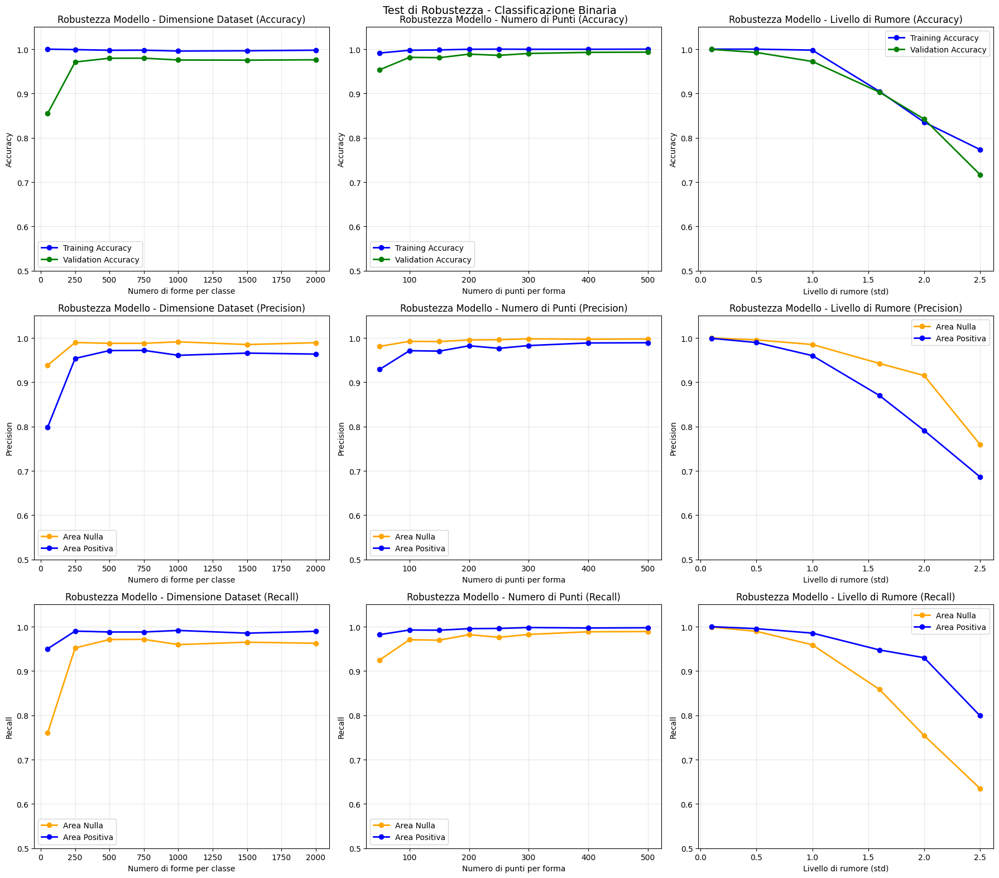

In [49]:
test_robustezza_binaria(gsSVM.best_estimator_)

### Random Forest

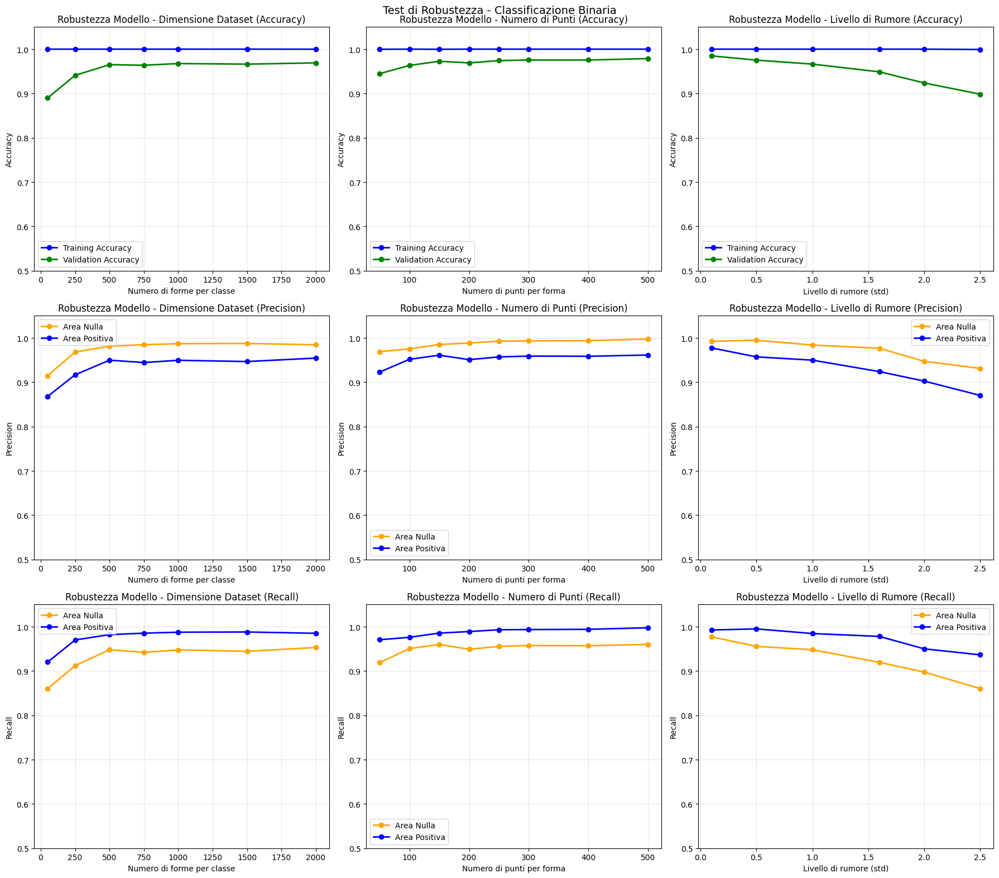

In [50]:
test_robustezza_binaria(gsRF.best_estimator_)

### Multilayer Perceptron

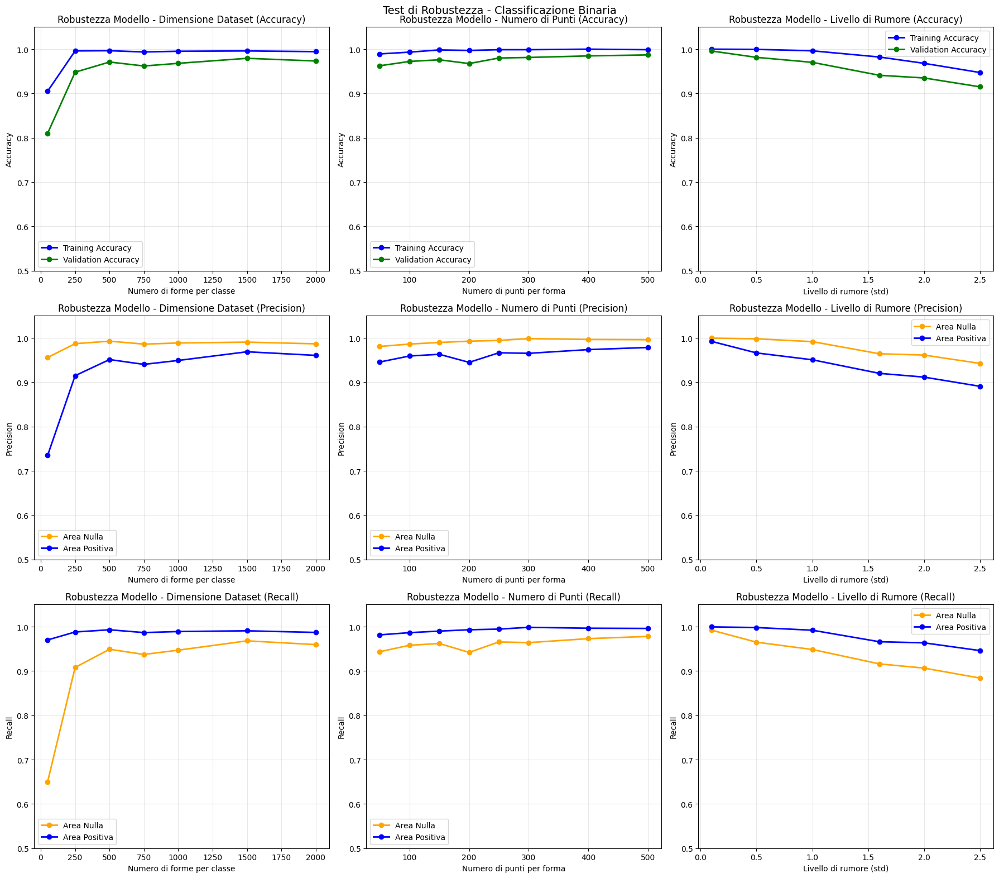

In [51]:
test_robustezza_binaria(gsMLP.best_estimator_)

### Logistic Regression

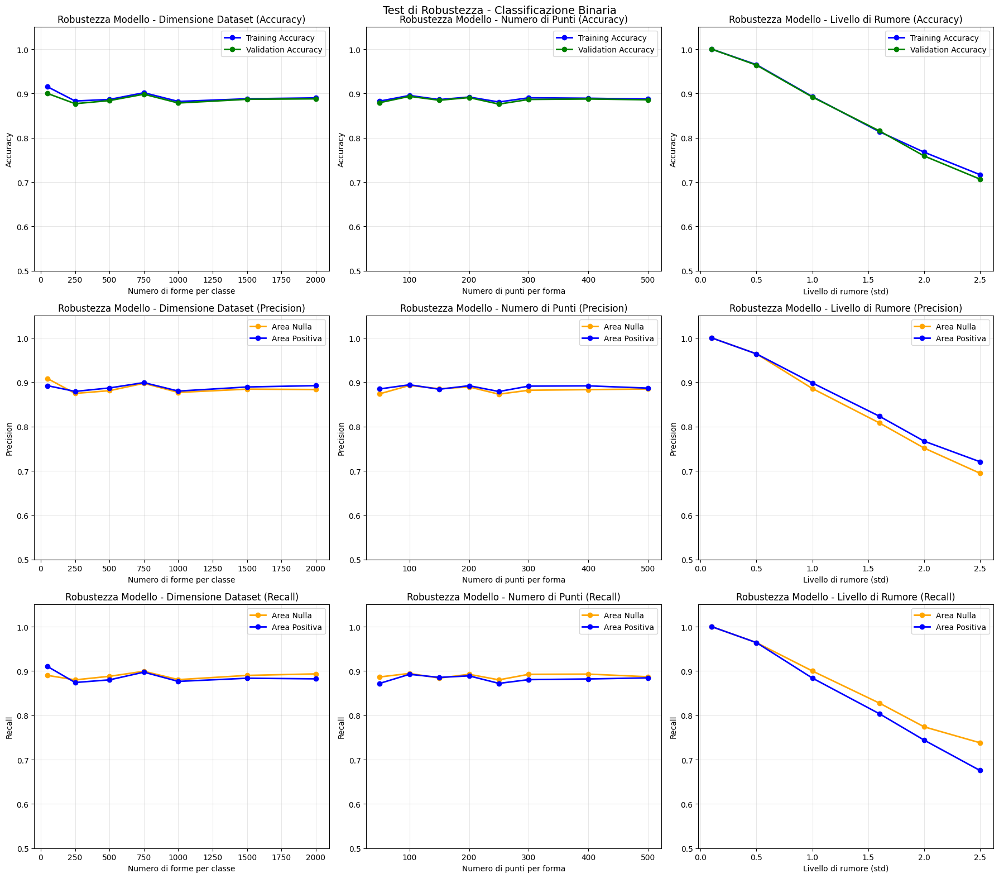

In [52]:
test_robustezza_binaria(gsLR.best_estimator_, usa_features_aggregate=True, sfs=sfs)